In [1]:
TOPIC = "Hourly Electricity Demand and Grid CO2 Emission Forecasting from EIA-930 Data with Global Gradient Boosting against the Official Day-ahead Forecast on Extreme Days"
GROUP = "Nhom 9"
PRIMARY_SOURCE = {"name": "EIA-930 Balance", "url": "https://www.eia.gov/electricity/gridmonitor/",
                   "license": "public domain (US government)",
                   "path": "data/raw/EIA930_BALANCE_2022_2024.csv"}
SECOND_SOURCE  = {"name": "EIA-930 8BA (CO2 emissions/intensity)", "url": "https://www.eia.gov/electricity/gridmonitor/",
                   "license": "public domain (US government)",
                   "path": "data/raw/EIA930_8BA_2022_2025.csv"}
EVENT_QUANTILE = 0.9
SEEDS = [0, 1, 2, 3, 4]
print("Topic:", TOPIC); print("Group:", GROUP)

Topic: Hourly Electricity Demand and Grid CO2 Emission Forecasting from EIA-930 Data with Global Gradient Boosting against the Official Day-ahead Forecast on Extreme Days
Group: Nhom 9


In [2]:
import pandas as pd, numpy as np, duckdb, json, hashlib, warnings, time, pickle
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore"); np.random.seed(42)
plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
TEAL, ACC, GREY = "#1B6B6D", "#F4A261", "#9FBFBF"

# ---- chart helpers: title/subtitle ABOVE the plot, "how to read" caption BELOW it (never on top of the data) ----
import textwrap
def describe_feature(f):
    """Plain-English meaning of a feature name (used in chart captions)."""
    if f == TARGET_COL: return "demand right now (forecast time)"
    if f.startswith("y_lag") and f[5:].isdigit():
        k = int(f[5:])
        extra = {24: " (same hour yesterday)", 48: " (same hour 2 days ago)", 168: " (same hour last week)"}.get(k, "")
        return f"demand {k} h ago{extra}"
    if f == "y_ma_season": return f"average demand, past {SEASON} h"
    if f == "y_sd_season": return f"spread (std) of demand, past {SEASON} h"
    if f == "y_diff1": return "change in demand vs 1 h ago"
    return f
def style(ax): ax.spines[["top", "right"]].set_visible(False)
def savefig(fig, name, title=None, subtitle=None, note=None):
    """Save fig. Optional title/subtitle go in reserved space above the axes and note in reserved space below,
    so the text never overlaps the chart. Without them it behaves like the old savefig."""
    w, h = fig.get_size_inches()
    t_lines = textwrap.wrap(title, int(w * 8.3)) if title else []
    s_lines = textwrap.wrap(subtitle, int(w * 12.5)) if subtitle else []
    n_lines = [l for p in (note or "").split("\n") for l in (textwrap.wrap(p, int(w * 12.5)) or [""])]
    top = 0.27 * len(t_lines) + 0.19 * len(s_lines) + (0.14 if (t_lines or s_lines) else 0)
    bot = (0.165 * len(n_lines) + 0.28) if n_lines else 0
    H = h + top + bot
    fig.set_size_inches(w, H)
    fig.tight_layout(rect=(0, bot / H, 1, 1 - top / H))
    y = 1 - 0.06 / H
    if t_lines:
        fig.text(0.012, y, "\n".join(t_lines), ha="left", va="top", fontsize=12, fontweight="bold"); y -= (0.27 * len(t_lines) + 0.03) / H
    if s_lines:
        fig.text(0.012, y, "\n".join(s_lines), ha="left", va="top", fontsize=9, color="#555555", linespacing=1.3)
    if n_lines:
        fig.text(0.012, (bot - 0.12) / H, "\n".join(n_lines), ha="left", va="top", fontsize=8.5, color="#333333", linespacing=1.3)
    fig.savefig(f"report/{name}.png", dpi=300); plt.close(fig); print("saved report/" + name + ".png")
# ---- end chart helpers ----

man = json.load(open("data/processed/manifest.json"))
assert hashlib.md5(open("data/processed/feat.parquet", "rb").read()).hexdigest() == man["md5"], "parquet khac manifest: chay lai Buoc 3 cua Notebook_C de tao ban moi"
UNIT_COL, TIME_COL, TARGET_COL, FREQ, HORIZONS, SEASON, TEST_START = man["unit_col"], man["time_col"], man["target_col"], man["freq"], man["horizons"], man["season"], man["test_start"]
EXOG_COLS = man["exog_cols"]
feat = pd.read_parquet("data/processed/feat.parquet"); feat[TIME_COL] = pd.to_datetime(feat[TIME_COL])
con = duckdb.connect(); con.register("feat", feat)
print("handover OK:", man["rows"], "rows,", man["units"], "units,", man["start"], "to", man["end"])
print("HORIZONS trong manifest:", HORIZONS)

handover OK: 1391895 rows, 53 units, 2022-01-01 06:00:00 to 2025-01-01 08:00:00
HORIZONS trong manifest: [24]


In [3]:
#Kiểm tra TEST_START còn nằm trong phạm vi dữ liệu
if pd.Timestamp(TEST_START) > feat[TIME_COL].max():
    print(f"manifest TEST_START={TEST_START} nam ngoai pham vi du lieu "
          f"({feat[TIME_COL].min()} -> {feat[TIME_COL].max()}); dat lai TEST_START moi")
else:
    print("TEST_START hop le:", TEST_START)

TEST_START hop le: 2024-07-01


## Bước 4: chia dữ liệu và mốc naive

**Ba cách chia, mỗi cách trả lời một câu hỏi**: (1) **theo thời gian** (huấn luyện trước `TEST_START`, kiểm thử sau) trả lời "mô hình có dùng được cho tương lai không"; (2) **lùi gốc dự báo** (rolling origin, nhiều điểm cắt) trả lời "kết quả có ổn định theo thời gian không"; (3) **để dành đơn vị** (leave-units-out) trả lời "mô hình có dùng cho trạm, vùng, khách hàng mới không".

**Mốc naive** là điều kiện tối thiểu: mô hình nào không thắng mốc naive thì không đáng báo cáo. Hai mốc: persistence (giá trị hiện tại) và naive mùa (giá trị cách đúng một mùa).

In [4]:
#Xác định horizon chính (h0) và tên cột target tương ứng
# HORIZONS lay tu manifest, vi du [24] hoac [1, 24, 168]
# h0 = tam du bao "chinh" de lam viec truoc (thuong la tam nho nhat hoac tam quan trong nhat)
H0 = HORIZONS[0]
Y = f"y_h{H0}"   # ten cot target ung voi tam H0, da tao san trong feat.parquet o Buoc 3

print("Cac tam du bao co san:", HORIZONS)
print("Tam dang lam viec (H0):", H0, "-> cot target:", Y)

Cac tam du bao co san: [24]
Tam dang lam viec (H0): 24 -> cot target: y_h24


In [5]:
#Liệt kê các cột sẽ dùng làm đặc trưng (feature) đầu vào
# lag_cols: cac cot tre (y_lag1, y_lag24...) va trung binh/do lech truot (y_ma_season, y_sd_season, y_diff1)
lag_cols = [c for c in feat.columns if c.startswith("y_lag") or c.startswith("y_ma") or c.startswith("y_sd") or c == "y_diff1"]

# exog_now: bien phu tuc thoi (CO2 tai chinh thoi diem do) - CHI dung neu ban chap nhan dung lam covariate
exog_now = [c for c in EXOG_COLS if c in feat.columns]

# exog_lag: bien phu bi tre SEASON buoc (an toan hon ve mat nhan qua/khong ro ri)
exog_lag = [c for c in feat.columns if c.endswith("_lag_season")]

# cal_cols: dac trung lich (gio, thu, thang, ngay trong nam)
cal_cols = [c for c in ["hr", "dow", "mon", "doy"] if c in feat.columns]

# ma hoa BA thanh so nguyen de mo hinh dung duoc (VD "AECI" -> 0, "PJM" -> 1, ...)
feat["unit_code"] = feat[UNIT_COL].astype("category").cat.codes

X_cols = [TARGET_COL] + lag_cols + exog_now + exog_lag + cal_cols + ["unit_code"]
print("So luong dac trung:", len(X_cols))
print("Danh sach dac trung:", X_cols)

So luong dac trung: 19
Danh sach dac trung: ['demand', 'y_lag1', 'y_lag2', 'y_lag3', 'y_lag24', 'y_lag48', 'y_lag168', 'y_ma_season', 'y_sd_season', 'y_diff1', 'co2_intensity_generated', 'co2_intensity_consumed', 'co2_intensity_generated_lag_season', 'co2_intensity_consumed_lag_season', 'hr', 'dow', 'mon', 'doy', 'unit_code']


In [6]:
#Bỏ các dòng thiếu đặc trưng hoặc thiếu target (thường ở đầu/cuối mỗi BA)
# Cac dong dau moi BA thieu y_lag168 (chua du 7 ngay lich su), cac dong cuoi thieu y_h24 (chua du du lieu tuong lai de lam target)
# -> bat buoc phai bo, neu khong mo hinh se hoc tren gia tri NaN hoac loi khi fit
need_cols = X_cols + [f"y_h{h}" for h in HORIZONS]
data = feat.dropna(subset=need_cols).copy()

print("So dong con lai sau khi bo thieu:", len(data), "/", len(feat), f"({len(data)/len(feat)*100:.1f}%)")
print("So BA con lai:", data[UNIT_COL].nunique())

So dong con lai sau khi bo thieu: 207518 / 1391895 (14.9%)
So BA con lai: 8


In [7]:
#Chia train/test theo thời gian (KHÔNG chia ngẫu nhiên, vì đây là time series)
# Train: tat ca du lieu TRUOC TEST_START. Test: tu TEST_START tro di.
# Chia theo thoi gian de mo phong dung tinh huong thuc te: mo hinh chi biet qua khu, du bao tuong lai.
train = data[data[TIME_COL] < pd.Timestamp(TEST_START)]
test  = data[data[TIME_COL] >= pd.Timestamp(TEST_START)]

X_tr, y_tr = train[X_cols], train[Y]
X_te, y_te = test[X_cols], test[Y]

assert len(train) > 0 and len(test) > 0, "train hoac test rong - kiem tra lai TEST_START"

print(f"Train: {len(train):,} dong, tu {train[TIME_COL].min().date()} den {train[TIME_COL].max().date()}")
print(f"Test : {len(test):,} dong, tu {test[TIME_COL].min().date()} den {test[TIME_COL].max().date()}")
print(f"Ty le test / tong: {len(test)/len(data)*100:.1f}%")

Train: 173,028 dong, tu 2022-01-08 den 2024-06-30
Test : 34,490 dong, tu 2024-07-01 den 2024-12-31
Ty le test / tong: 16.6%


In [8]:
#Mốc naive: persistence (giữ nguyên giá trị hiện tại)
from sklearn.metrics import mean_absolute_error as MAE

# Persistence: du bao gia tri tai thoi diem t+h = gia tri tai thoi diem t (khong doi)
# Day la mo hinh "ngu ngoc nhat co the chap nhan duoc" - bat cu mo hinh nao thua cai nay la khong dung duoc
pers_pred = test[TARGET_COL].values   # gia tri demand HIEN TAI, dung lam du bao cho tuong lai
pers_mae = MAE(test[Y].values, pers_pred)

print(f"Persistence baseline (h={H0}): MAE = {pers_mae:,.1f} MW")

Persistence baseline (h=24): MAE = 340.1 MW


In [9]:
#Mốc naive: seasonal naive (giá trị cùng giờ này của một mùa trước)
# Seasonal naive: du bao gia tri tai t+h = gia tri tai t - SEASON (VD 24 gio truoc, tuc cung gio hom qua)
# Chi hop le khi h <= SEASON (neu h > SEASON, dung tam persistence thay the vi khong co cot y_lag phu hop)
lag_col = f"y_lag{SEASON}"
if H0 <= SEASON and lag_col in test.columns:
    seas_pred = test[lag_col].values
else:
    seas_pred = test[TARGET_COL].values  # fallback ve persistence neu tam qua xa

seas_mae = MAE(test[Y].values, seas_pred)
print(f"Seasonal-naive baseline (h={H0}): MAE = {seas_mae:,.1f} MW")

Seasonal-naive baseline (h=24): MAE = 506.0 MW


In [10]:
#So sánh 2 mốc naive cho MỌI horizon trong HORIZONS (không chỉ H0)
naive_summary = []
for h in HORIZONS:
    y_true = test[f"y_h{h}"].values
    pers = test[TARGET_COL].values
    pers_mae_h = MAE(y_true, pers)

    lag_col_h = f"y_lag{SEASON}"
    if h <= SEASON and lag_col_h in test.columns:
        seas = test[lag_col_h].values
    else:
        seas = pers
    seas_mae_h = MAE(y_true, seas)

    naive_summary.append([h, round(pers_mae_h, 1), round(seas_mae_h, 1)])
    print(f"h={h:>3}: persistence MAE={pers_mae_h:,.1f} | seasonal-naive MAE={seas_mae_h:,.1f}")

naive_df = pd.DataFrame(naive_summary, columns=["horizon", "persistence_mae", "seasonal_naive_mae"])
naive_df.to_csv("report/table_naive_baselines.csv", index=False)
display(naive_df)

h= 24: persistence MAE=340.1 | seasonal-naive MAE=506.0


,horizon,persistence_mae,seasonal_naive_mae
0,24,340.1,506.0


In [11]:
#Hàm mốc naive dùng chung (để tái sử dụng nhiều lần, không lặp code)
def naive_preds(frame, h):
    # persistence: gia tri hien tai (demand tai thoi diem t)
    pers = frame[TARGET_COL].values
    # seasonal naive: gia tri cach h buoc (VD 24h truoc). Neu h > SEASON thi fallback ve persistence
    seas = frame[f"y_lag{SEASON}"].values if h <= SEASON and f"y_lag{SEASON}" in frame.columns else frame[TARGET_COL].values
    return pers, seas

In [12]:
#Hàm tính 4 chỉ số đánh giá (MAE, RMSE, sMAPE, MASE)
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE

def smape(y, p):
    # % sai so doi xung, +1e-9 de tranh chia cho 0
    return float(np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p) + 1e-9)) * 100)

def mase(y, p, frame, h):
    # MASE = sai so mo hinh / sai so seasonal-naive (tinh tren TRAIN)
    # MASE < 1: tot hon moc naive | MASE > 1: te hon moc naive
    scale = np.mean(np.abs(train[f"y_h{h}"].values - naive_preds(train, h)[1])) + 1e-9
    return float(np.mean(np.abs(y - p)) / scale)

def metrics(y, p, frame, h):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"MAE": MAE(y, p), "RMSE": MSE(y, p) ** 0.5, "sMAPE": smape(y, p), "MASE": mase(y, p, frame, h)}

# kiem tra: seasonal naive so voi chinh no phai ra MASE = 1
print(metrics(y_te.values, naive_preds(test, H0)[1], test, H0))

{'MAE': 505.9571697800604, 'RMSE': 1098.569151741802, 'sMAPE': 7.1678689620896945, 'MASE': 1.0760771596320693}


## Bước 6a: sáu họ mô hình, năm seed, mọi tầm dự báo

**Họ mô hình và lý do chọn**: naive mùa (điều kiện tối thiểu); ridge với trễ (tuyến tính, nhanh, khó overfit); random forest (phi tuyến, ít siêu tham số); LightGBM toàn cục (mạnh nhất cho bảng đặc trưng, học chung nhiều đơn vị); tuyến tính dài hạn (LTSF-Linear: một lớp tuyến tính từ cửa sổ trễ, mốc mạnh của các bài mô hình nền); mô hình nền zero-shot (Chronos, TimesFM: không huấn luyện, dự báo từ ngữ cảnh, đại diện cho xu hướng 2024-2025).

**Năm seed**: mô hình có ngẫu nhiên (random forest, LightGBM) chạy 5 lần; báo trung bình và độ lệch chuẩn. Nếu chênh lệch giữa hai mô hình nhỏ hơn hai lần độ lệch chuẩn thì không kết luận mô hình nào hơn.

In [13]:
#Khai báo 4 họ mô hình có thể huấn luyện
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor

def make_models(seed):
    return {
        "Ridge": Ridge(alpha=1.0),
        "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=seed),
        "LightGBM_global": LGBMRegressor(n_estimators=800, learning_rate=0.03, num_leaves=31,
                                          subsample=0.8, colsample_bytree=0.8, random_state=seed, verbose=-1),
        "LTSF_Linear": Ridge(alpha=0.1),  # LTSF-Linear = hoi quy tuyen tinh, chi dung cua so tre
    }

# LTSF_Linear chi dung cac cot lag (khong dung CO2/lich) - dung dung y tuong "duong tuyen tinh tu qua khu"
LTSF_COLS = [c for c in lag_cols if c.startswith("y_lag")] + [TARGET_COL]
print("6 ho mo hinh:", list(make_models(0).keys()) + ["Persistence", "SeasonalNaive", "Chronos_zero_shot"])

6 ho mo hinh: ['Ridge', 'RandomForest', 'LightGBM_global', 'LTSF_Linear', 'Persistence', 'SeasonalNaive', 'Chronos_zero_shot']


In [14]:
#Chạy tất cả mô hình × seed × tầm dự báo, lưu từng dòng kết quả
results, preds = [], {}

for h in HORIZONS:
    ytr, yte = train[f"y_h{h}"].values, test[f"y_h{h}"].values
    pers, seas = naive_preds(test, h)

    # 2 moc naive - khong ngau nhien nen chi can chay 1 lan
    for name, p in [("Persistence", pers), ("SeasonalNaive", seas)]:
        results.append({"model": name, "h": h, "seed": 0, **metrics(yte, p, test, h)})
        if h == H0:
            preds[name] = p

    # Ridge/LTSF_Linear khong ngau nhien -> chay 1 seed. RandomForest/LightGBM ngau nhien -> chay du 5 seed
    for seed in SEEDS:
        for name, model in make_models(seed).items():
            if name in ("Ridge", "LTSF_Linear") and seed != SEEDS[0]:
                continue
            cols = LTSF_COLS if name == "LTSF_Linear" else X_cols
            model.fit(train[cols], ytr)
            p = model.predict(test[cols])
            results.append({"model": name, "h": h, "seed": seed, **metrics(yte, p, test, h)})
            if h == H0 and seed == 0:
                preds[name] = p

res = pd.DataFrame(results)
res.to_csv("report/table_rq2_raw.csv", index=False)

summary = res.groupby(["model", "h"])[["MAE", "RMSE", "sMAPE", "MASE"]].agg(["mean", "std"]).round(4)
summary.to_csv("report/table_rq2_summary.csv")
display(summary)

MAE               RMSE           sMAPE          \
                        mean     std       mean     std    mean     std   
model           h                                                         
LTSF_Linear     24  339.4744     NaN   727.2227     NaN  5.1336     NaN   
LightGBM_global 24  282.5828  1.5126   595.2350  5.3277  4.2695  0.0143   
Persistence     24  340.1211     NaN   752.2469     NaN  5.0760     NaN   
RandomForest    24  277.9364  0.1503   574.6327  0.4142  4.2294  0.0008   
Ridge           24  345.5418     NaN   707.0561     NaN  5.5979     NaN   
SeasonalNaive   24  505.9572     NaN  1098.5692     NaN  7.1679     NaN   

                      MASE          
                      mean     std  
model           h                   
LTSF_Linear     24  0.7220     NaN  
LightGBM_global 24  0.6010  0.0032  
Persistence     24  0.7234     NaN  
RandomForest    24  0.5911  0.0003  
Ridge           24  0.7349     NaN  
SeasonalNaive   24  1.0761     NaN

In [15]:
# Step 6a-2b: quy đổi sMAPE ra "độ chính xác" (%) cho từng model, viết thành bảng
acc_tbl = res[res.h == H0].groupby("model")["sMAPE"].mean().sort_values()
acc_tbl = (100 - acc_tbl).round(2).to_frame("accuracy_%")
acc_tbl["MASE"] = res[res.h == H0].groupby("model")["MASE"].mean().round(3)
acc_tbl = acc_tbl.sort_values("accuracy_%", ascending=False)
acc_tbl.to_csv("report/table_rq2_accuracy.csv")
display(acc_tbl)

,accuracy_%,MASE
model,,
RandomForest,95.77,0.591
LightGBM_global,95.73,0.601
Persistence,94.92,0.723
LTSF_Linear,94.87,0.722
Ridge,94.40,0.735
SeasonalNaive,92.83,1.076


In [16]:
# Step 6b-1: event classifier — dự báo giờ nào là "cực đoan" (demand ở decile trên/dưới của chính từng BA)
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# ngưỡng tính THEO TỪNG BA, chỉ dùng phân phối của TRAIN để tránh rò rỉ từ tương lai
q_hi = train.groupby(UNIT_COL)[Y].quantile(EVENT_QUANTILE)
q_lo = train.groupby(UNIT_COL)[Y].quantile(1 - EVENT_QUANTILE)
def flag_extreme(frame):
    hi = frame[UNIT_COL].map(q_hi); lo = frame[UNIT_COL].map(q_lo)
    return ((frame[Y] >= hi) | (frame[Y] <= lo)).astype(int)

yb_tr, yb_te = flag_extreme(train).values, flag_extreme(test).values
print("tỷ lệ giờ cực đoan - train:", yb_tr.mean().round(3), "| test:", yb_te.mean().round(3))

clf = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31,
                      subsample=0.8, colsample_bytree=0.8, random_state=0, verbose=-1)
clf.fit(train[X_cols], yb_tr)
p_ev = clf.predict_proba(test[X_cols])[:, 1]     # <- biến p_ev mà exercise 5, 6 đang cần
yhat_ev = (p_ev >= 0.5).astype(int)

acc  = accuracy_score(yb_te, yhat_ev)
prec = precision_score(yb_te, yhat_ev, zero_division=0)
rec  = recall_score(yb_te, yhat_ev, zero_division=0)
f1   = f1_score(yb_te, yhat_ev, zero_division=0)
auc  = roc_auc_score(yb_te, p_ev)

print(f"Event classifier (EVENT_QUANTILE={EVENT_QUANTILE}):")
print(f"  accuracy={acc:.3f}  precision={prec:.3f}  recall={rec:.3f}  f1={f1:.3f}  AUC={auc:.3f}")

pd.DataFrame([{"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "auc": auc}]) \
  .to_csv("report/table_rq3_event_classifier.csv", index=False)

tỷ lệ giờ cực đoan - train: 0.2 | test: 0.253
Event classifier (EVENT_QUANTILE=0.9):
  accuracy=0.923  precision=0.877  recall=0.810  f1=0.842  AUC=0.969


In [17]:
imp = pd.Series(clf.feature_importances_, index=X_cols).sort_values(ascending=False)
display(imp.head(10))

doy                        1782
demand                     1757
dow                        1146
y_ma_season                1054
unit_code                   982
hr                          886
y_sd_season                 869
y_lag48                     738
y_lag168                    687
co2_intensity_generated     677
dtype: int32

In [18]:
#Mô hình nền zero-shot (Chronos) — tự bỏ qua nếu chưa cài
fm_rows = []
try:
    from chronos import ChronosPipeline
    import torch
    pipe = ChronosPipeline.from_pretrained("amazon/chronos-t5-small", device_map="cpu")

    CTX = min(512, 8 * SEASON)
    n_units = min(5, test[UNIT_COL].nunique())
    yt_all, yp_all = [], []

    for u in test[UNIT_COL].unique()[:n_units]:
        hist = data[(data[UNIT_COL] == u) & (data[TIME_COL] < pd.Timestamp(TEST_START))][TARGET_COL].values[-CTX:]
        fut = test[test[UNIT_COL] == u].sort_values(TIME_COL)[TARGET_COL].values
        ctx = list(hist); k = 0
        while k + H0 <= len(fut):
            fc = pipe.predict(torch.tensor(np.array(ctx[-CTX:], dtype=float)), prediction_length=H0).median(dim=1).values.numpy().ravel()
            yp_all.extend(fc); yt_all.extend(fut[k:k + H0]); ctx.extend(fut[k:k + H0])
            k += H0
            if k > 8 * H0:
                break

    yt_all, yp_all = np.array(yt_all), np.array(yp_all)
    fm_rows.append({"model": "Chronos_zero_shot", "h": H0, "seed": 0, **metrics(yt_all, yp_all, test, H0)})
    print("Chronos danh gia tren", len(yt_all), "buoc")
except Exception as e:
    print("bo qua mo hinh nen (chua cai dat):", str(e)[:120])
    print("-> ghi vao Discussion nhu mot gioi han, hoac chay tren Colab: pip install chronos-forecasting")

if fm_rows:
    res = pd.concat([res, pd.DataFrame(fm_rows)])
    res.to_csv("report/table_rq2_raw.csv", index=False)
    display(res)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Chronos danh gia tren 1080 buoc


,model,h,seed,MAE,RMSE,sMAPE,MASE
0,Persistence,24,0,340.121116,752.246945,5.075973,0.723375
1,SeasonalNaive,24,0,505.957170,1098.569152,7.167869,1.076077
2,Ridge,24,0,345.541774,707.056075,5.597864,0.734903
3,RandomForest,24,0,277.983686,574.446094,4.230073,0.591220
4,LightGBM_global,24,0,283.007062,595.284314,4.283351,0.601904
5,LTSF_Linear,24,0,339.474402,727.222709,5.133573,0.721999
6,RandomForest,24,1,277.995261,574.874033,4.230397,0.591244
7,LightGBM_global,24,1,282.063052,592.582133,4.264712,0.599896
8,RandomForest,24,2,278.121150,575.208217,4.229177,0.591512
9,LightGBM_global,24,2,280.507507,588.577786,4.250401,0.596587


In [19]:
# Step 6a-3b: LSTM (PyTorch) — dùng cửa sổ trễ y_lag1..y_lagK làm chuỗi đầu vào, dự báo y_h{H0}
try:
    import torch, torch.nn as nn
    from sklearn.preprocessing import StandardScaler

    # 1) chọn các cột lag thuần (không lấy y_ma/y_sd/y_diff1), sắp theo thứ tự thời gian tăng dần
    seq_lag_cols = sorted(
        [c for c in lag_cols if c.startswith("y_lag")],
        key=lambda c: int(c.replace("y_lag", ""))
    )[::-1]   # lag xa nhất đứng đầu chuỗi, lag gần nhất (y_lag1) đứng cuối -> đúng thứ tự thời gian
    SEQ_LEN = len(seq_lag_cols)
    print("LSTM sequence length:", SEQ_LEN, "|", seq_lag_cols)

    # 2) chuẩn hoá bằng thống kê của TRAIN thôi (tránh rò rỉ), demand và các lag cùng đơn vị nên dùng chung 1 scaler
    scaler = StandardScaler().fit(train[[TARGET_COL]].values)
    def to_seq(frame):
        Xs = scaler.transform(frame[seq_lag_cols].values.reshape(-1, 1)).reshape(-1, SEQ_LEN, 1)
        ys = scaler.transform(frame[[Y]].values).ravel()
        return torch.tensor(Xs, dtype=torch.float32), torch.tensor(ys, dtype=torch.float32)

    Xtr_t, ytr_t = to_seq(train)
    Xte_t, yte_t = to_seq(test)

    # 3) model nhỏ gọn, đủ dùng cho bài tập (không cần quá sâu)
    class LSTMRegressor(nn.Module):
        def __init__(self, hidden=64):
            super().__init__()
            self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, batch_first=True)
            self.head = nn.Linear(hidden, 1)
        def forward(self, x):
            out, _ = self.lstm(x)
            return self.head(out[:, -1, :]).squeeze(-1)   # chỉ lấy hidden state ở bước cuối

    device = "cuda" if torch.cuda.is_available() else "cpu"
    torch.manual_seed(0)
    lstm = LSTMRegressor().to(device)
    opt = torch.optim.Adam(lstm.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()

    # 4) train theo batch (subsample nếu train quá lớn, để chạy được trên CPU trong thời gian hợp lý)
    ds = torch.utils.data.TensorDataset(Xtr_t, ytr_t)
    dl = torch.utils.data.DataLoader(ds, batch_size=256, shuffle=True)
    EPOCHS = 8
    for ep in range(EPOCHS):
        lstm.train(); tot = 0.0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); pred = lstm(xb); loss = loss_fn(pred, yb)
            loss.backward(); opt.step(); tot += loss.item() * len(xb)
        print(f"epoch {ep+1}/{EPOCHS} - train MSE (scaled): {tot/len(ds):.4f}")

    # 5) dự báo trên test, đưa về thang gốc (MW), tính metrics giống các model khác, ghép vào res/preds
    lstm.eval()
    with torch.no_grad():
        p_scaled = lstm(Xte_t.to(device)).cpu().numpy()
    p_lstm = scaler.inverse_transform(p_scaled.reshape(-1, 1)).ravel()

    row = {"model": "LSTM", "h": H0, "seed": 0, **metrics(yte, p_lstm, test, H0)}
    res = pd.concat([res, pd.DataFrame([row])], ignore_index=True)
    preds["LSTM"] = p_lstm
    res.to_csv("report/table_rq2_raw.csv", index=False)
    print("LSTM MAE:", round(row["MAE"], 2), "| MASE:", round(row["MASE"], 3))
except Exception as e:
    print("LSTM skipped:", repr(e)[:200], "-> báo vào phần hạn chế nếu không chạy được (thiếu torch, hết RAM, ...)")

LSTM sequence length: 6 | ['y_lag168', 'y_lag48', 'y_lag24', 'y_lag3', 'y_lag2', 'y_lag1']
epoch 1/8 - train MSE (scaled): 0.0461
epoch 2/8 - train MSE (scaled): 0.0137
epoch 3/8 - train MSE (scaled): 0.0134
epoch 4/8 - train MSE (scaled): 0.0128
epoch 5/8 - train MSE (scaled): 0.0120
epoch 6/8 - train MSE (scaled): 0.0107
epoch 7/8 - train MSE (scaled): 0.0096
epoch 8/8 - train MSE (scaled): 0.0091
LSTM MAE: 398.17 | MASE: 0.847


saved report/fig_rq2_models.png
Wilcoxon RandomForest vs LightGBM_global: p = 1.15e-06
-> Only conclude 'significantly better' if p < 0.01 AND the difference is greater than 2 times the standard deviation across seeds.


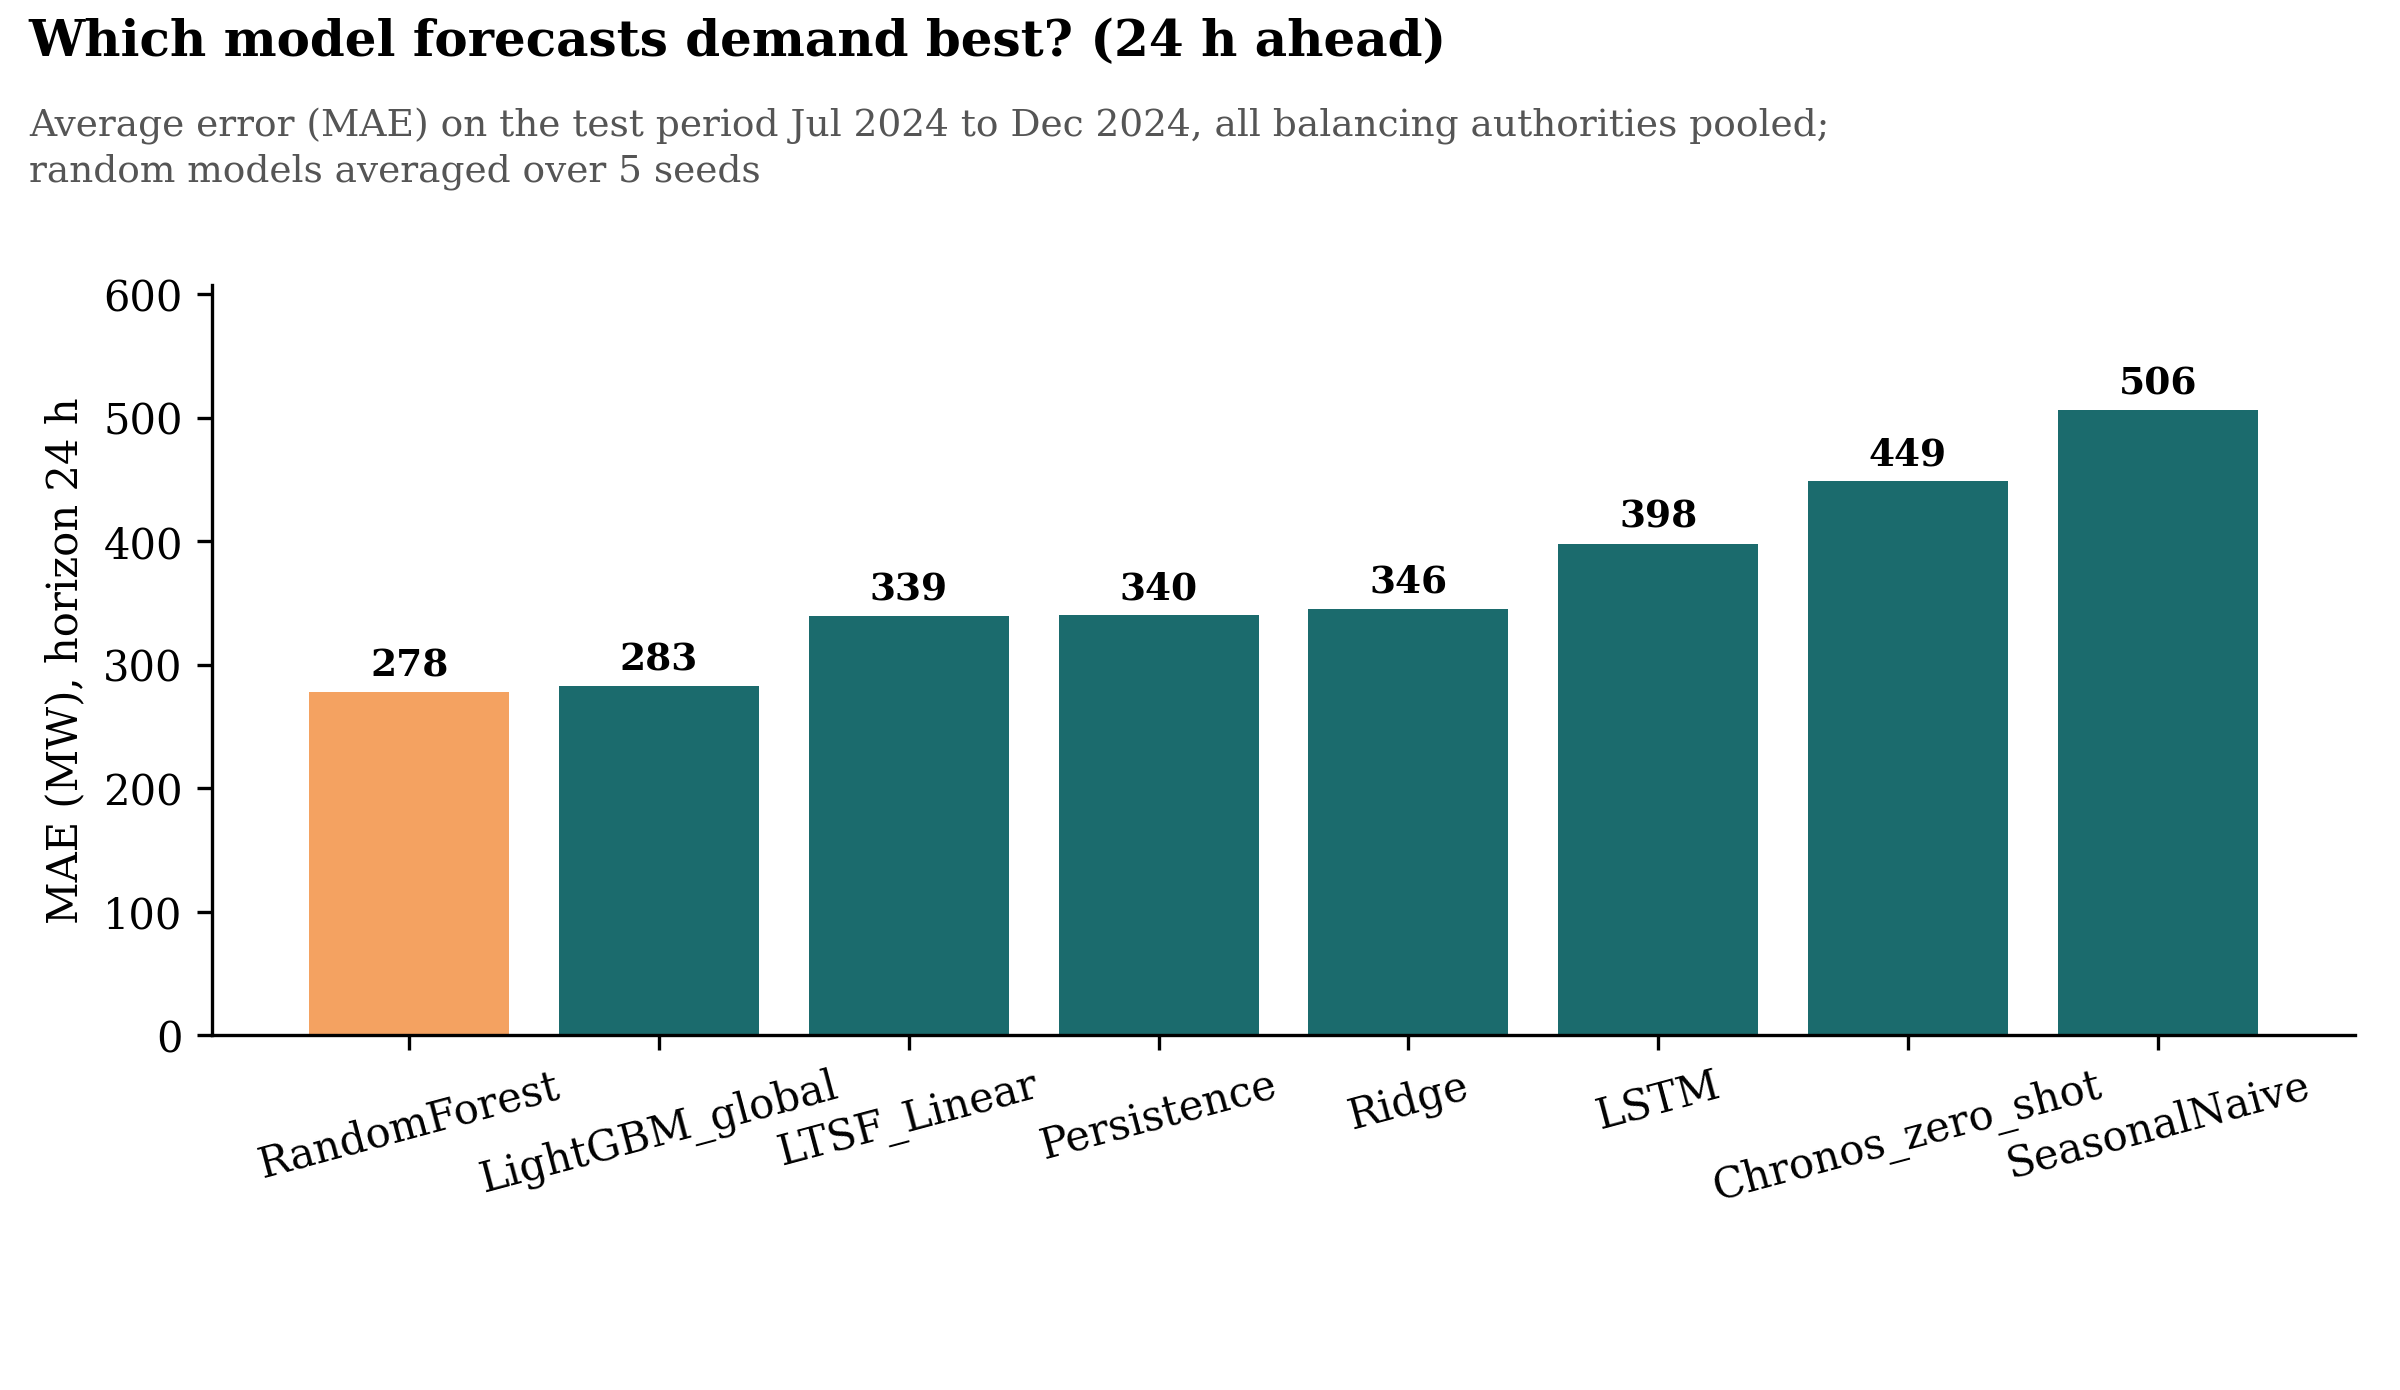

In [20]:
#Biểu đồ so sánh chính + kiểm định ý nghĩa thống kê
from IPython.display import Image
main = res[res.h == H0].groupby("model").MAE.agg(["mean", "std"]).sort_values("mean")

# text for the figure: what it shows, how to read it, headline number
best_m = main.index[0]
def _gain(base):   # % error reduction of the best model vs one baseline
    if base in main.index and base != best_m:
        return f"{(1 - main['mean'][best_m] / main['mean'][base]) * 100:.0f}% lower than {base}"
gains = " and ".join(g for g in (_gain("SeasonalNaive"), _gain("Persistence")) if g)


fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.bar(main.index, main["mean"], color=[ACC if i == 0 else TEAL for i in range(len(main))])
ax.bar_label(bars, fmt="%.3g", fontweight="bold", fontsize=9, padding=2)
ax.set_ylabel(f"MAE (MW), horizon {H0} h"); ax.set_ylim(0, main["mean"].max() * 1.2)
plt.setp(ax.get_xticklabels(), rotation=15); style(ax)
savefig(fig, "fig_rq2_models",
        title=f"Which model forecasts demand best? ({H0} h ahead)",
        subtitle=f"Average error (MAE) on the test period {test[TIME_COL].min():%b %Y} to {test[TIME_COL].max():%b %Y}, all balancing authorities pooled; random models averaged over {len(SEEDS)} seeds",
)
plt.show()

from scipy.stats import wilcoxon
best_name, runner = main.index[0], main.index[1]
if best_name in preds and runner in preds:
    e1 = np.abs(y_te.values - preds[best_name])
    e2 = np.abs(y_te.values - preds[runner])
    print(f"Wilcoxon {best_name} vs {runner}: p = {wilcoxon(e1, e2).pvalue:.2e}")
    print("-> Only conclude 'significantly better' if p < 0.01 AND the difference is greater than 2 times the standard deviation across seeds.")

from IPython.display import Image, display
# Hiển thị ảnh đã lưu ngay bên dưới
display(Image(filename="report/fig_rq2_models.png"))

saved report/fig_rq2_horizon.png


model,Chronos_zero_shot,LSTM,LTSF_Linear,LightGBM_global,Persistence,RandomForest,Ridge,SeasonalNaive
h,,,,,,,,
24,448.7701,398.1653,339.4744,282.5828,340.1211,277.9364,345.5418,505.9572


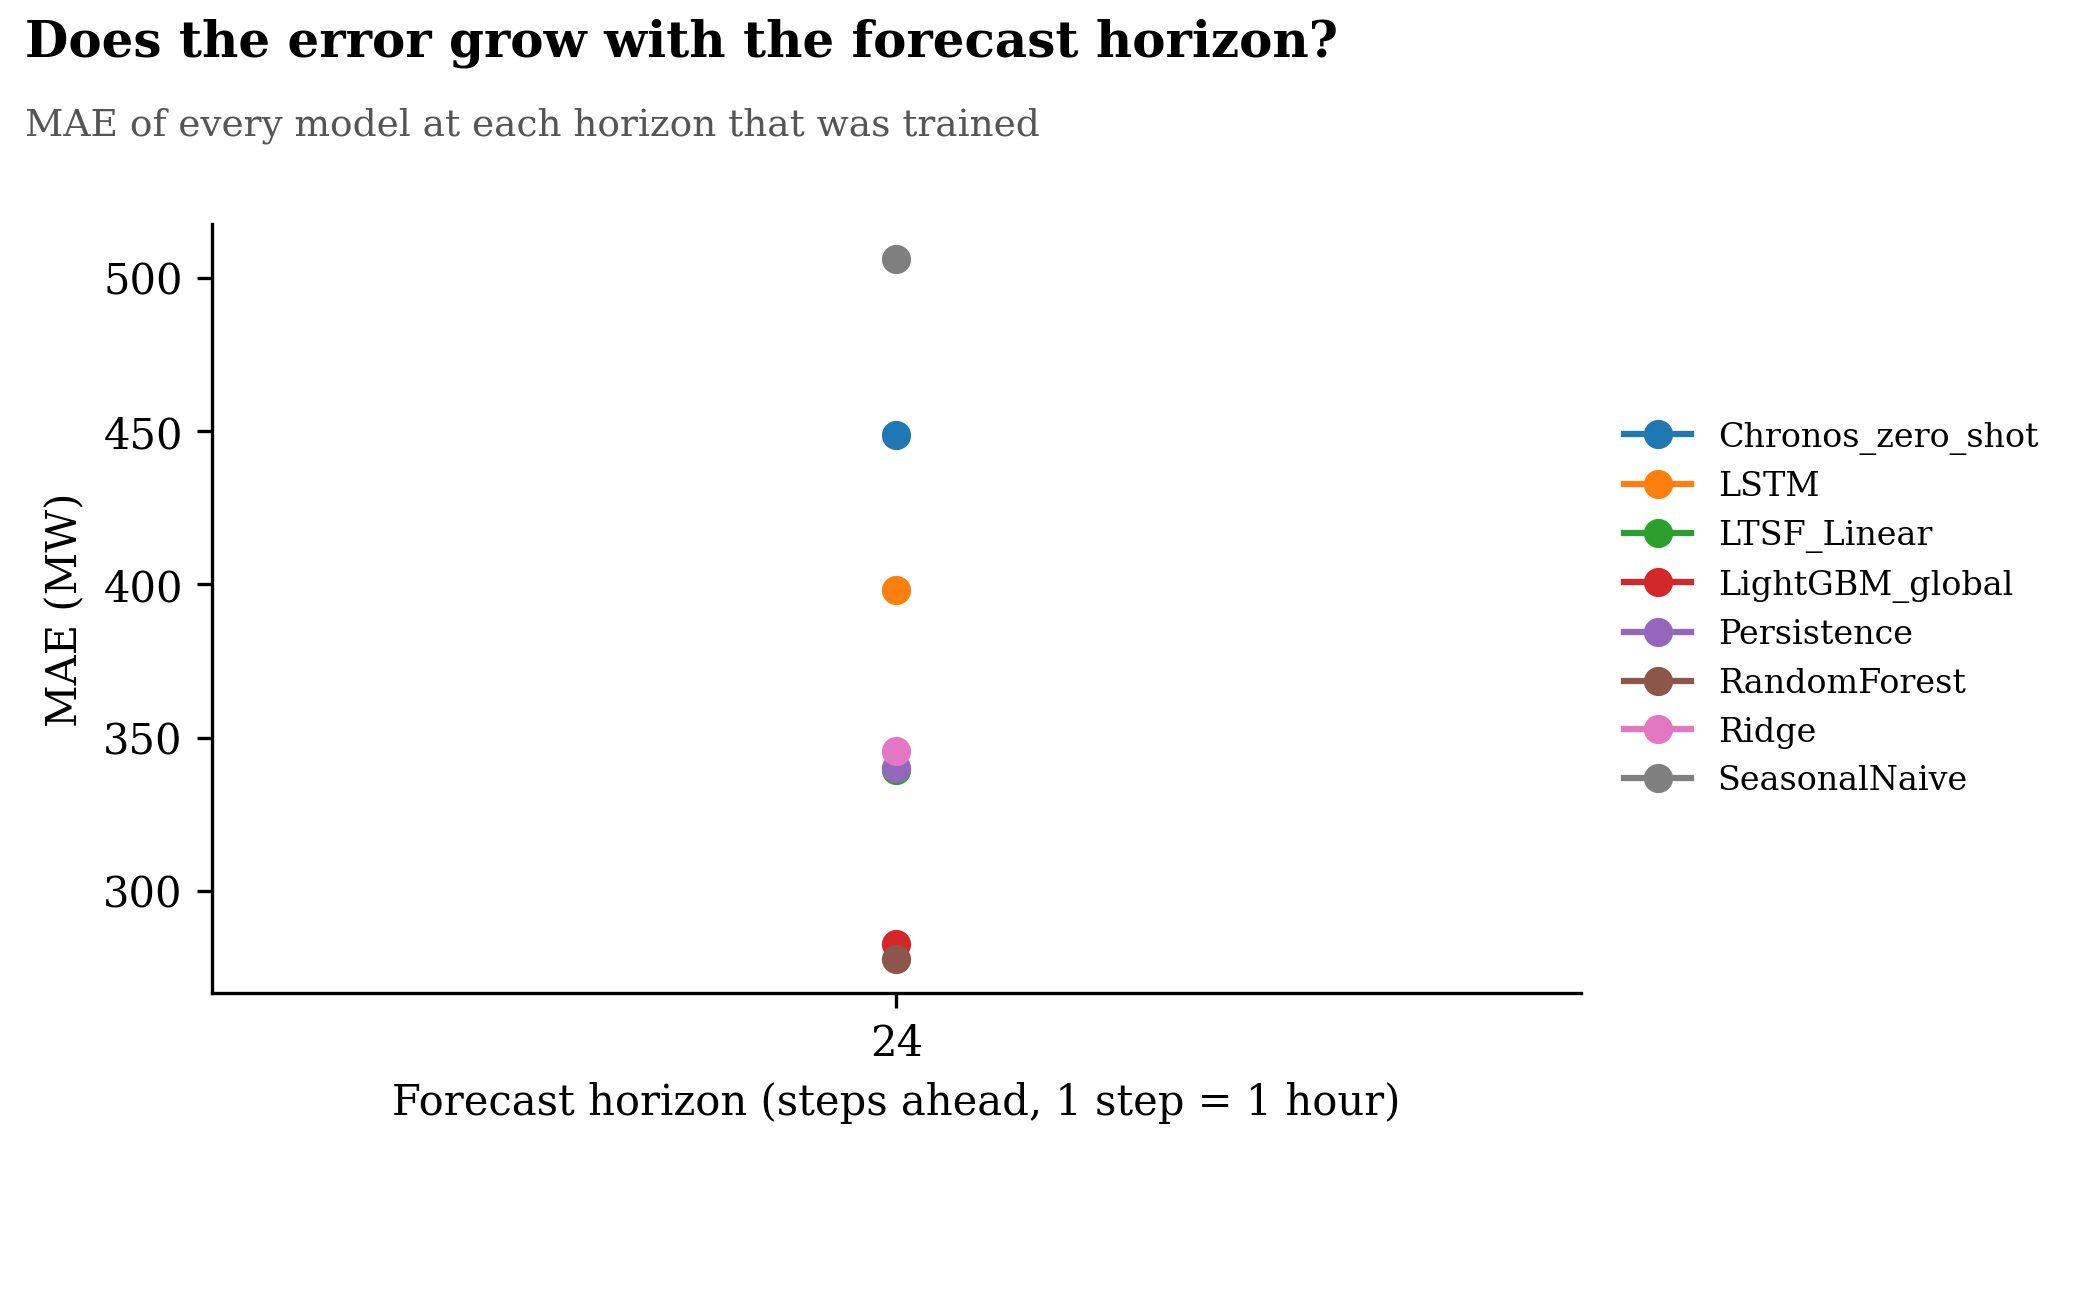

In [21]:
#Sai số theo từng tầm dự báo (chỉ có ý nghĩa nếu HORIZONS có nhiều hơn 1 giá trị)
byh = res.groupby(["model", "h"]).MAE.mean().unstack(0)

fig, ax = plt.subplots(figsize=(7, 3.3))
for m in byh.columns:
    ax.plot(byh.index, byh[m], marker="o", label=m)
ax.set_xticks(list(byh.index))
ax.set_xlabel("Forecast horizon (steps ahead, 1 step = 1 hour)"); ax.set_ylabel("MAE (MW)")
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5)); style(ax)

    
savefig(fig, "fig_rq2_horizon",
        title="Does the error grow with the forecast horizon?",
        subtitle="MAE of every model at each horizon that was trained",
)

byh.round(4).to_csv("report/table_rq2_by_horizon.csv")
display(byh.round(4))

display(Image(filename="report/fig_rq2_horizon.png"))

In [22]:
#Chọn mô hình tốt nhất để dùng tiếp cho RQ2 sâu hơn / RQ3 / SHAP
best_name = [m for m in main.index if m in make_models(0)][0]
best = make_models(0)[best_name]
best_cols = LTSF_COLS if best_name == "LTSF_Linear" else X_cols

best.fit(train[best_cols], y_tr)
pred_best = best.predict(test[best_cols])

print("Mo hinh tot nhat (co the huan luyen):", best_name, "| MAE =", round(MAE(y_te, pred_best), 4))

Mo hinh tot nhat (co the huan luyen): RandomForest | MAE = 277.9837


### Tinh chỉnh siêu tham số: chỉ khi đáng

**Quy tắc**: tinh chỉnh chỉ có ý nghĩa nếu chênh lệch giữa mô hình tốt nhất và mô hình kế tiếp lớn hơn hai lần độ lệch chuẩn theo seed; nếu không thì thời gian nên dành cho đặc trưng và dữ liệu. Dùng `TimeSeriesSplit` để không rò rỉ tương lai trong tinh chỉnh.

In [23]:
# Quy tắc: chỉ tinh chỉnh nếu mô hình tốt nhất là LightGBM VÀ chênh lệch với model kế tiếp
# lớn hơn 2 lần độ lệch chuẩn (nếu không, RandomForest đã thắng LightGBM rõ ràng rồi -> không cần)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

gap = main["mean"].iloc[1] - main["mean"].iloc[0]
sd = res[(res.h == H0) & (res.model == main.index[0])].MAE.std()
sd = 0.0 if sd != sd else sd  # NaN -> 0

if best_name == "LightGBM_global" and gap > 2 * sd:
    grid = {
        "num_leaves": [15, 31, 63],
        "learning_rate": [0.01, 0.03, 0.1],
        "n_estimators": [400, 800, 1500],
        "min_child_samples": [10, 20, 50],
    }
    rs = RandomizedSearchCV(
        LGBMRegressor(random_state=0, verbose=-1), grid, n_iter=8,
        cv=TimeSeriesSplit(4), scoring="neg_mean_absolute_error",
        random_state=0, n_jobs=-1
    ).fit(X_tr, y_tr)
    tuned_mae = MAE(y_te, rs.best_estimator_.predict(X_te))
    print("Best params:", rs.best_params_)
    print("Tuned MAE:", round(tuned_mae, 4), "| Default MAE:", round(MAE(y_te, pred_best), 4))
    if tuned_mae < MAE(y_te, pred_best):
        best = rs.best_estimator_
        pred_best = best.predict(X_te)
else:
    if best_name != "LightGBM_global":
        print(f"Bỏ qua tinh chỉnh: mô hình tốt nhất là {best_name}, không phải LightGBM")
    else:
        print(f"Bỏ qua tinh chỉnh: chênh lệch {gap:.4g} nằm trong nhiễu seed (2×std = {2*sd:.4g})")

Bỏ qua tinh chỉnh: mô hình tốt nhất là RandomForest, không phải LightGBM


saved report/fig_rq2_actual_vs_pred.png
saved report/fig_rq2_error_by_calendar.png


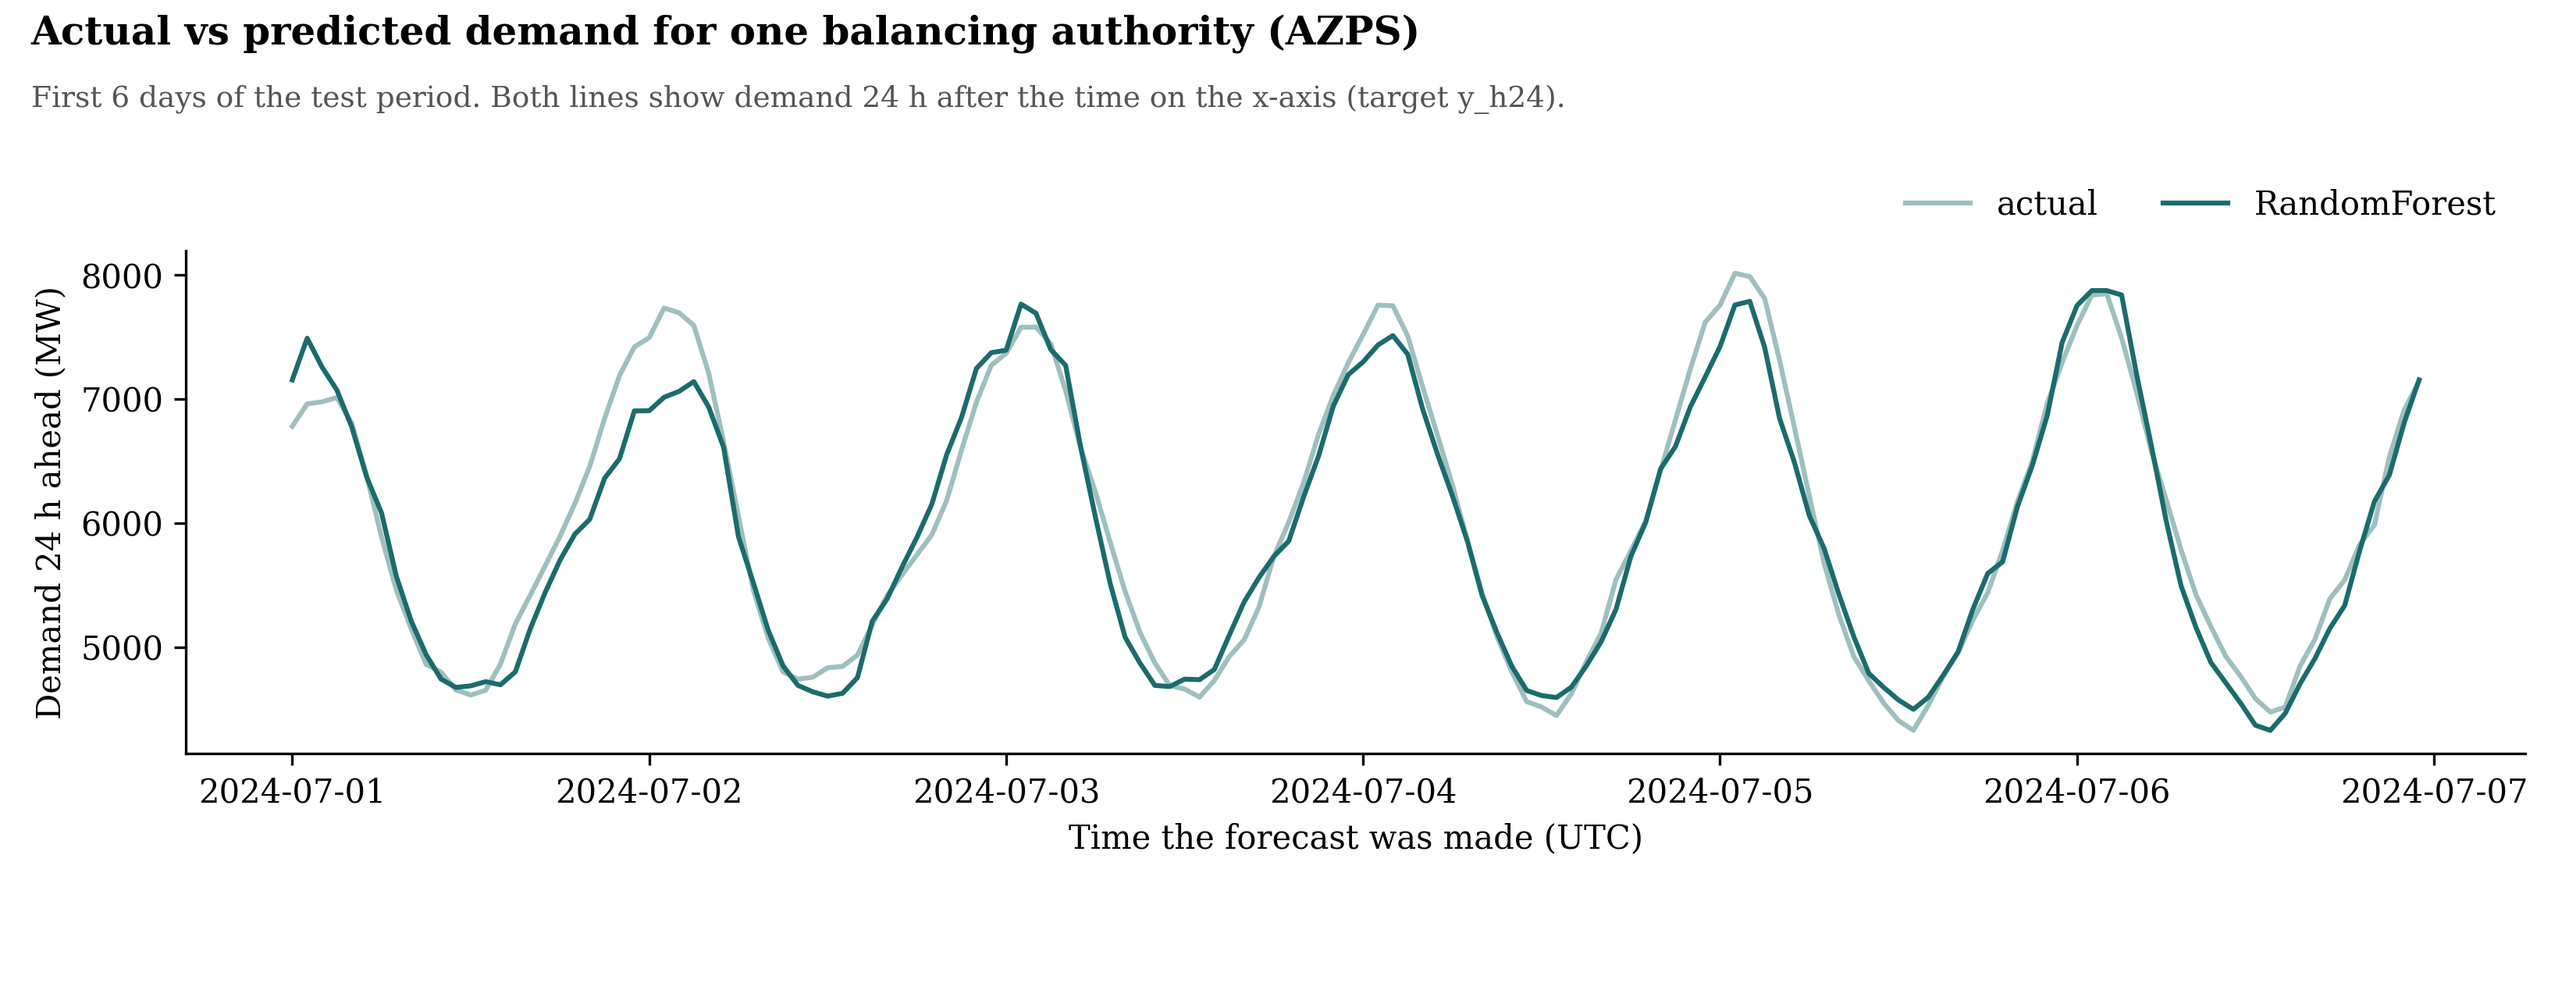

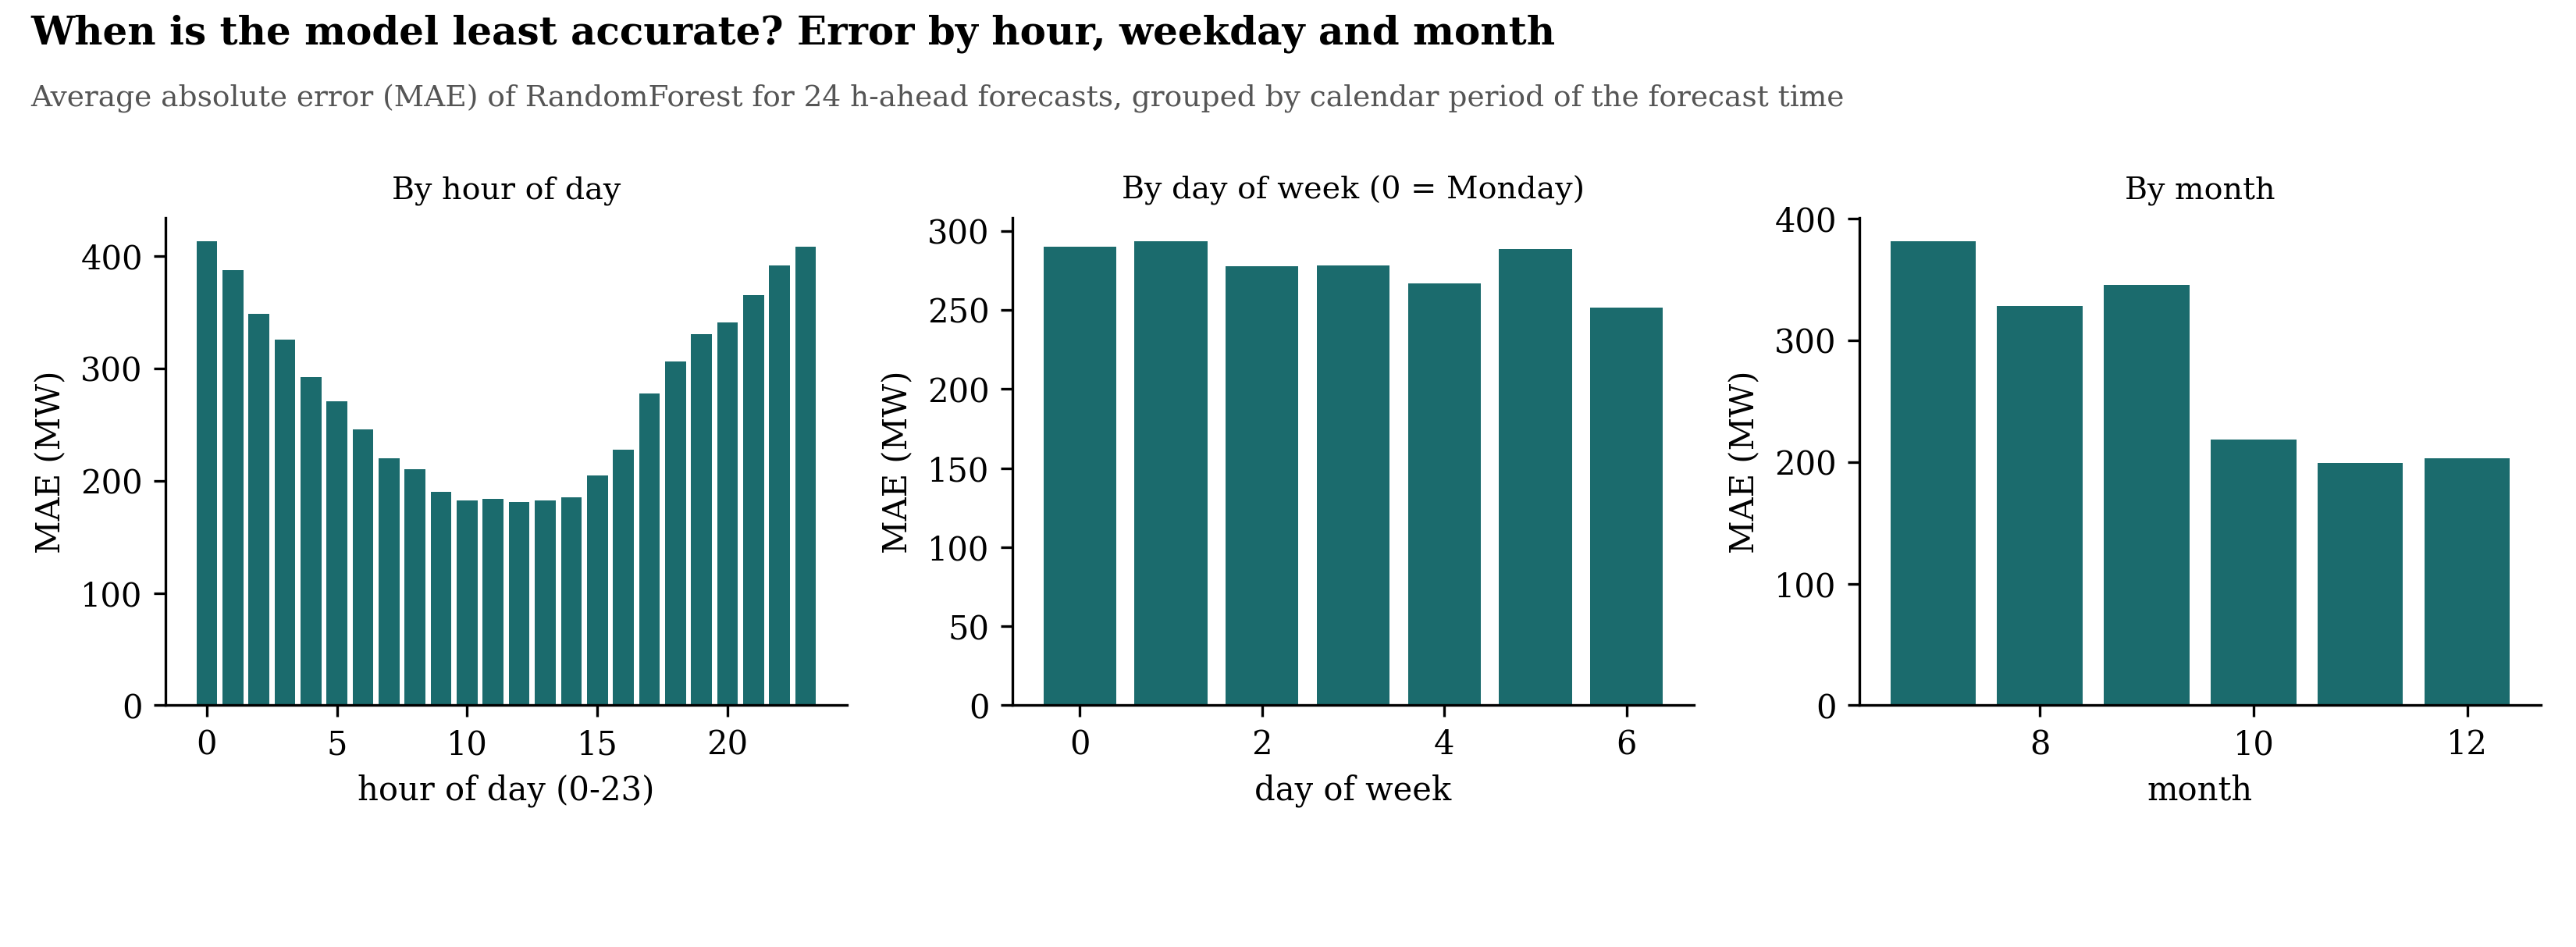

In [24]:
#Vẽ actual vs predicted + sai số theo lịch (giờ/thứ/tháng)
# Chọn 1 BA bất kỳ trong test để xem mô hình dự báo khớp thực tế đến đâu (6 mùa đầu tiên = 6*24 giờ)
u0 = test[UNIT_COL].unique()[0]
g = test[test[UNIT_COL] == u0].assign(
    pred=pred_best[test[UNIT_COL].values == u0]
).sort_values(TIME_COL).head(6 * SEASON)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(g[TIME_COL], g[Y], color=GREY, label="actual")
ax.plot(g[TIME_COL], g.pred, color=TEAL, label=best_name)
ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0))   # legend sits above the plot, not on the lines
ax.set_xlabel("Time the forecast was made (UTC)")
ax.set_ylabel(f"Demand {H0} h ahead (MW)")
style(ax)
savefig(fig, "fig_rq2_actual_vs_pred",
        title=f"Actual vs predicted demand for one balancing authority ({u0})",
        subtitle=f"First {len(g) // SEASON} days of the test period. Both lines show demand {H0} h after the time on the x-axis (target {Y}).",
)

# Sai số trung bình theo giờ trong ngày / thứ trong tuần / tháng -> xem mô hình yếu ở khung giờ nào
err = test.assign(err=np.abs(y_te.values - pred_best))
ttl = {"hr": "By hour of day", "dow": "By day of week (0 = Monday)", "mon": "By month"}
xl = {"hr": "hour of day (0-23)", "dow": "day of week", "mon": "month"}
fig, axes = plt.subplots(1, len(cal_cols[:3]), figsize=(11, 3.0))
for ax, k in zip(np.atleast_1d(axes), cal_cols[:3]):
    s = err.groupby(k).err.mean()
    ax.bar(s.index, s.values, color=TEAL)
    ax.set_title(ttl.get(k, k), fontsize=9.5)
    ax.set_xlabel(xl.get(k, k))
    ax.set_ylabel("MAE (MW)")
    style(ax)
savefig(fig, "fig_rq2_error_by_calendar",
        title="When is the model least accurate? Error by hour, weekday and month",
        subtitle=f"Average absolute error (MAE) of {best_name} for {H0} h-ahead forecasts, grouped by calendar period of the forecast time",
)

display(Image(filename="report/fig_rq2_actual_vs_pred.png"))
display(Image(filename="report/fig_rq2_error_by_calendar.png"))

Cell 23 — Ghi chú (markdown, không cần chạy code)

RQ2 sâu hơn: kiểm tra 2 câu hỏi

Rolling-origin: kết quả có ổn định theo thời gian không?
Leave-units-out: mô hình có dùng được cho BA (vùng điện) mới chưa từng thấy không?

## RQ2 sâu hơn: tổng quát hoá theo thời gian và theo đơn vị

**Lùi gốc dự báo (rolling origin)**: huấn luyện đến điểm cắt k, kiểm thử một cửa sổ sau đó, lặp 4-6 lần. Nếu MAE dao động mạnh giữa các cửa sổ, kết quả phụ thuộc giai đoạn và bài phải báo khoảng. **Để dành đơn vị**: giữ 20% đơn vị hoàn toàn ngoài huấn luyện; tổn thất so với đơn vị đã thấy cho biết mô hình có "học chung" hay chỉ nhớ từng đơn vị.

,cut,rows,MAE_model,MAE_seasonal_naive
0,2024-07-31,5862,319.7056,590.4471
1,2024-08-31,5834,337.8615,599.0971
2,2024-09-30,5852,216.0588,485.7262
3,2024-10-31,5763,193.0854,363.9977
4,2024-11-30,5864,199.4013,356.2959


saved report/fig_rq2_rolling.png


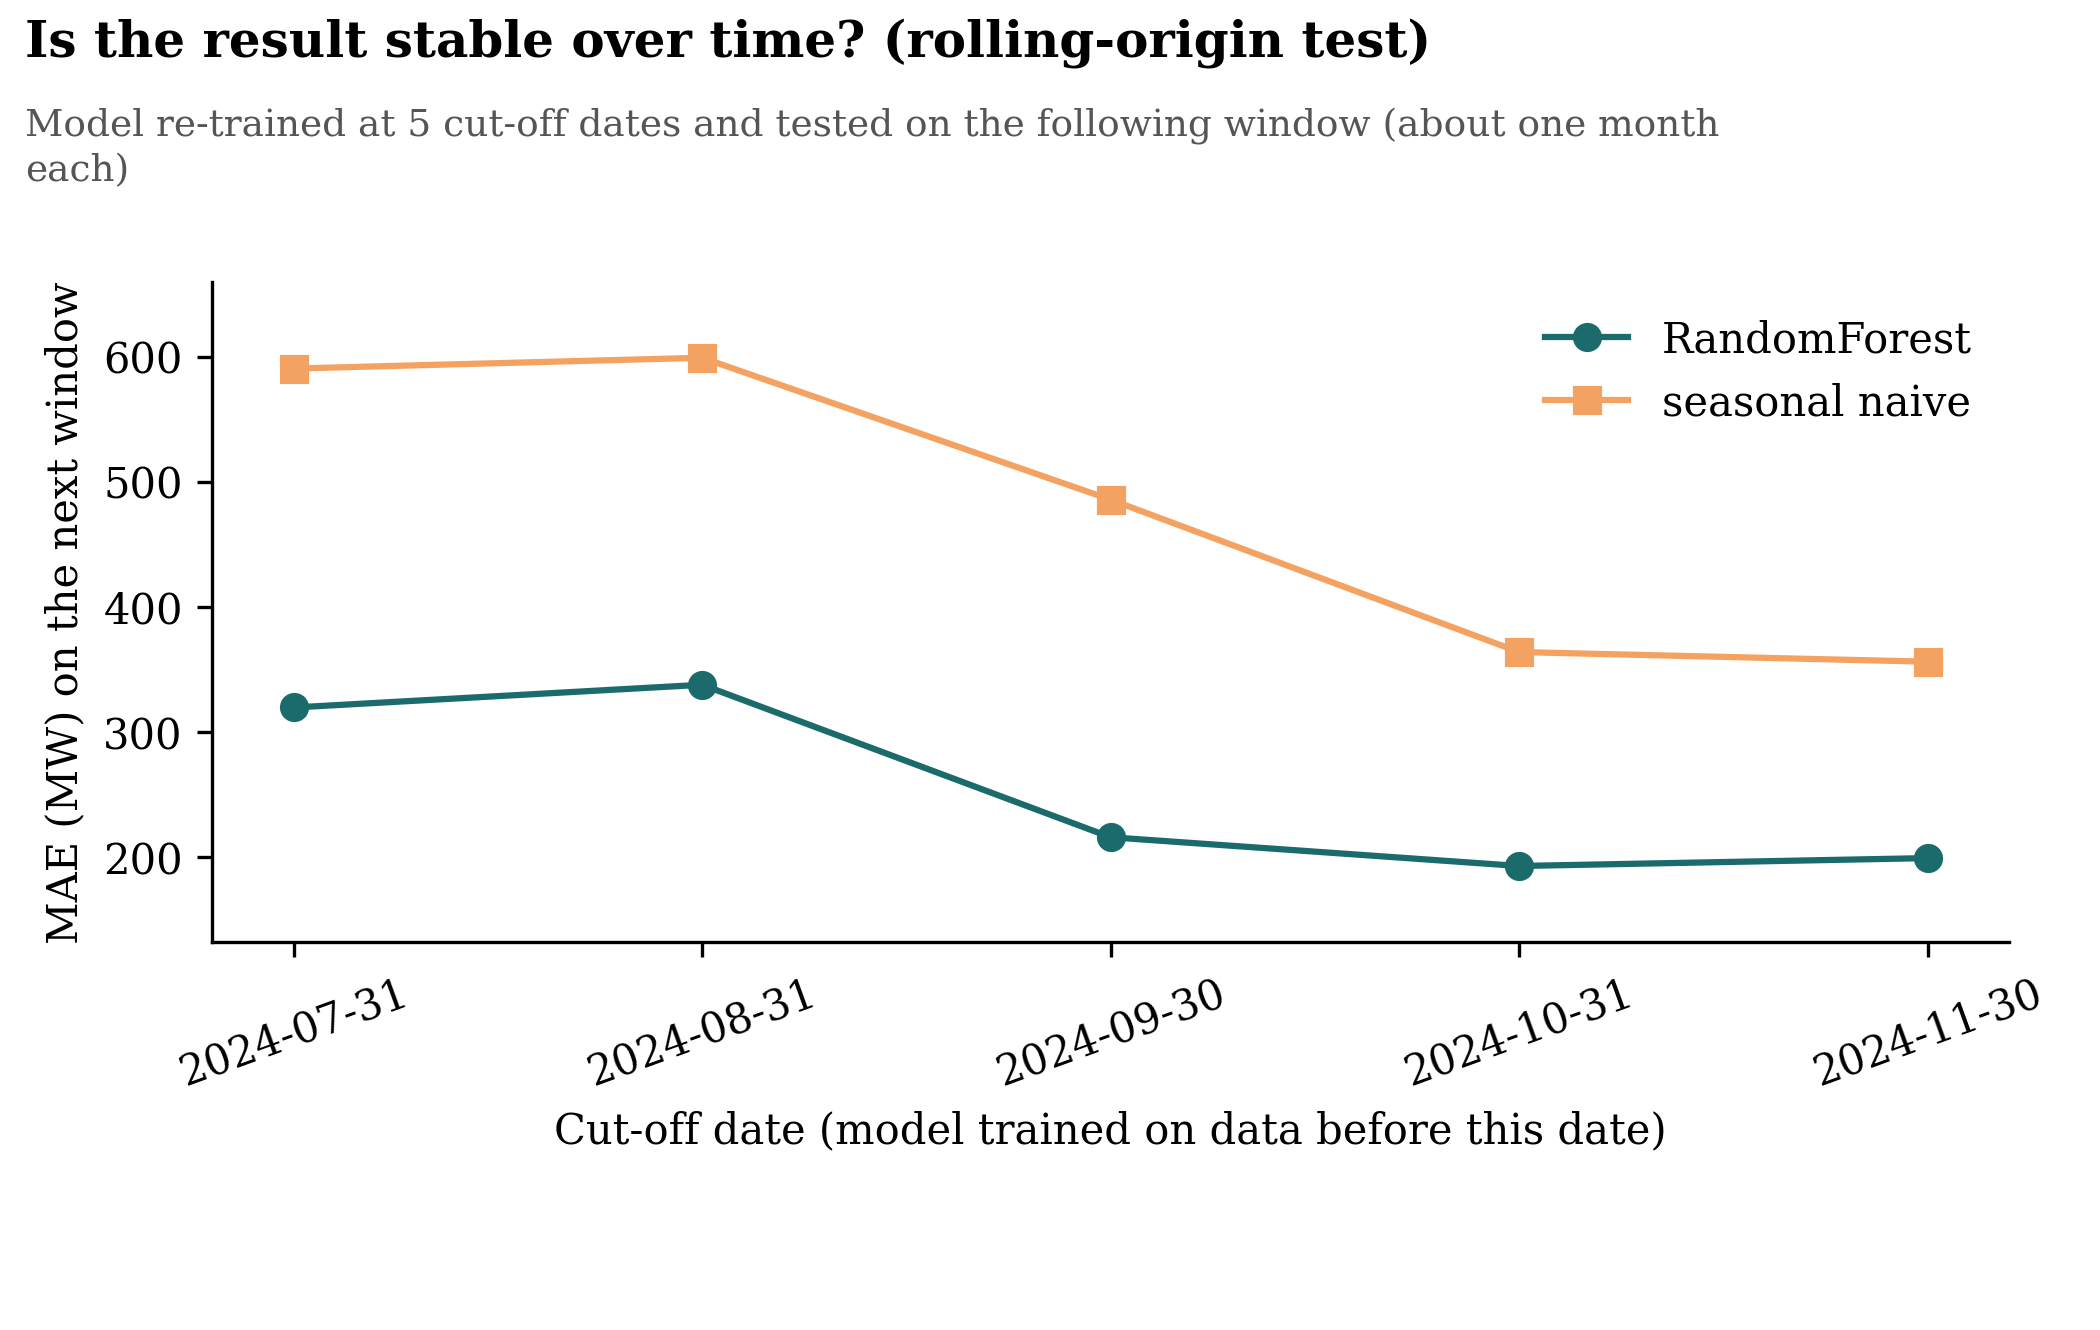

In [25]:
#Rolling-origin (lùi gốc dự báo, 5 điểm cắt)
# Chia tập test thành 5 giai đoạn liên tiếp, mỗi giai đoạn train lại và test riêng
# Nếu MAE dao động mạnh giữa các giai đoạn -> kết quả phụ thuộc vào thời điểm, cần báo khoảng dao động
cuts = pd.date_range(pd.Timestamp(TEST_START), data[TIME_COL].max(), periods=7)[1:-1]
rows = []
for c in cuts:
    tr_r = data[data[TIME_COL] < c]
    te_r = data[(data[TIME_COL] >= c) & (data[TIME_COL] < c + (cuts[1] - cuts[0]))]
    if len(te_r) < 100:
        continue
    m_r = make_models(0)[best_name].fit(tr_r[best_cols], tr_r[Y])
    p_r = m_r.predict(te_r[best_cols])
    rows.append([c.date(), len(te_r), MAE(te_r[Y], p_r), MAE(te_r[Y], naive_preds(te_r, H0)[1])])

roll = pd.DataFrame(rows, columns=["cut", "rows", "MAE_model", "MAE_seasonal_naive"]).round(4)
roll.to_csv("report/table_rq2_rolling.csv", index=False)
display(roll)

wins = int((roll.MAE_model < roll.MAE_seasonal_naive).sum())
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(roll.cut.astype(str), roll.MAE_model, marker="o", color=TEAL, label=best_name)
ax.plot(roll.cut.astype(str), roll.MAE_seasonal_naive, marker="s", color=ACC, label="seasonal naive")
ax.legend(frameon=False, loc="upper right")
ax.margins(y=0.15)
ax.set_xlabel("Cut-off date (model trained on data before this date)")
ax.set_ylabel("MAE (MW) on the next window")
plt.setp(ax.get_xticklabels(), rotation=20)
style(ax)
savefig(fig, "fig_rq2_rolling",
        title="Is the result stable over time? (rolling-origin test)",
        subtitle=f"Model re-trained at {len(roll)} cut-off dates and tested on the following window (about one month each)",
)

display(Image(filename="report/fig_rq2_rolling.png"))

In [26]:
#Leave-units-out (giữ 20% BA hoàn toàn ngoài huấn luyện)
# Giữ 20% BA (vùng điện) không cho model thấy lúc train, rồi so sánh:
# "seen units" (BA đã thấy) vs "unseen units" (BA hoàn toàn mới)
units = data[UNIT_COL].unique()
rs = np.random.RandomState(42)
hold = rs.choice(units, max(1, len(units) // 5), replace=False)

tr_u = train[~train[UNIT_COL].isin(hold)]
te_seen = test[~test[UNIT_COL].isin(hold)]
te_unseen = test[test[UNIT_COL].isin(hold)]

cols_u = [c for c in best_cols if c != "unit_code"]  # bỏ unit_code vì BA mới không có mã này lúc train
m_u = make_models(0)[best_name].fit(tr_u[cols_u], tr_u[Y])

lou = pd.DataFrame([
    ["seen units", MAE(te_seen[Y], m_u.predict(te_seen[cols_u])), MAE(te_seen[Y], naive_preds(te_seen, H0)[1])],
    ["unseen units", MAE(te_unseen[Y], m_u.predict(te_unseen[cols_u])), MAE(te_unseen[Y], naive_preds(te_unseen, H0)[1])],
], columns=["group", "MAE_model", "MAE_seasonal_naive"]).round(4)

lou.to_csv("report/table_rq2_unseen_units.csv", index=False)
display(lou)
print("Tổn thất tương đối trên BA mới:", round(lou.MAE_model.iloc[1] / lou.MAE_model.iloc[0] - 1, 3))

,group,MAE_model,MAE_seasonal_naive
0,seen units,294.2159,526.0699
1,unseen units,545.3624,366.7110


Tổn thất tương đối trên BA mới: 0.854


saved report/fig_rq2_per_unit.png
BA khó dự báo nhất: ['PGE', 'SRP', 'LDWP']


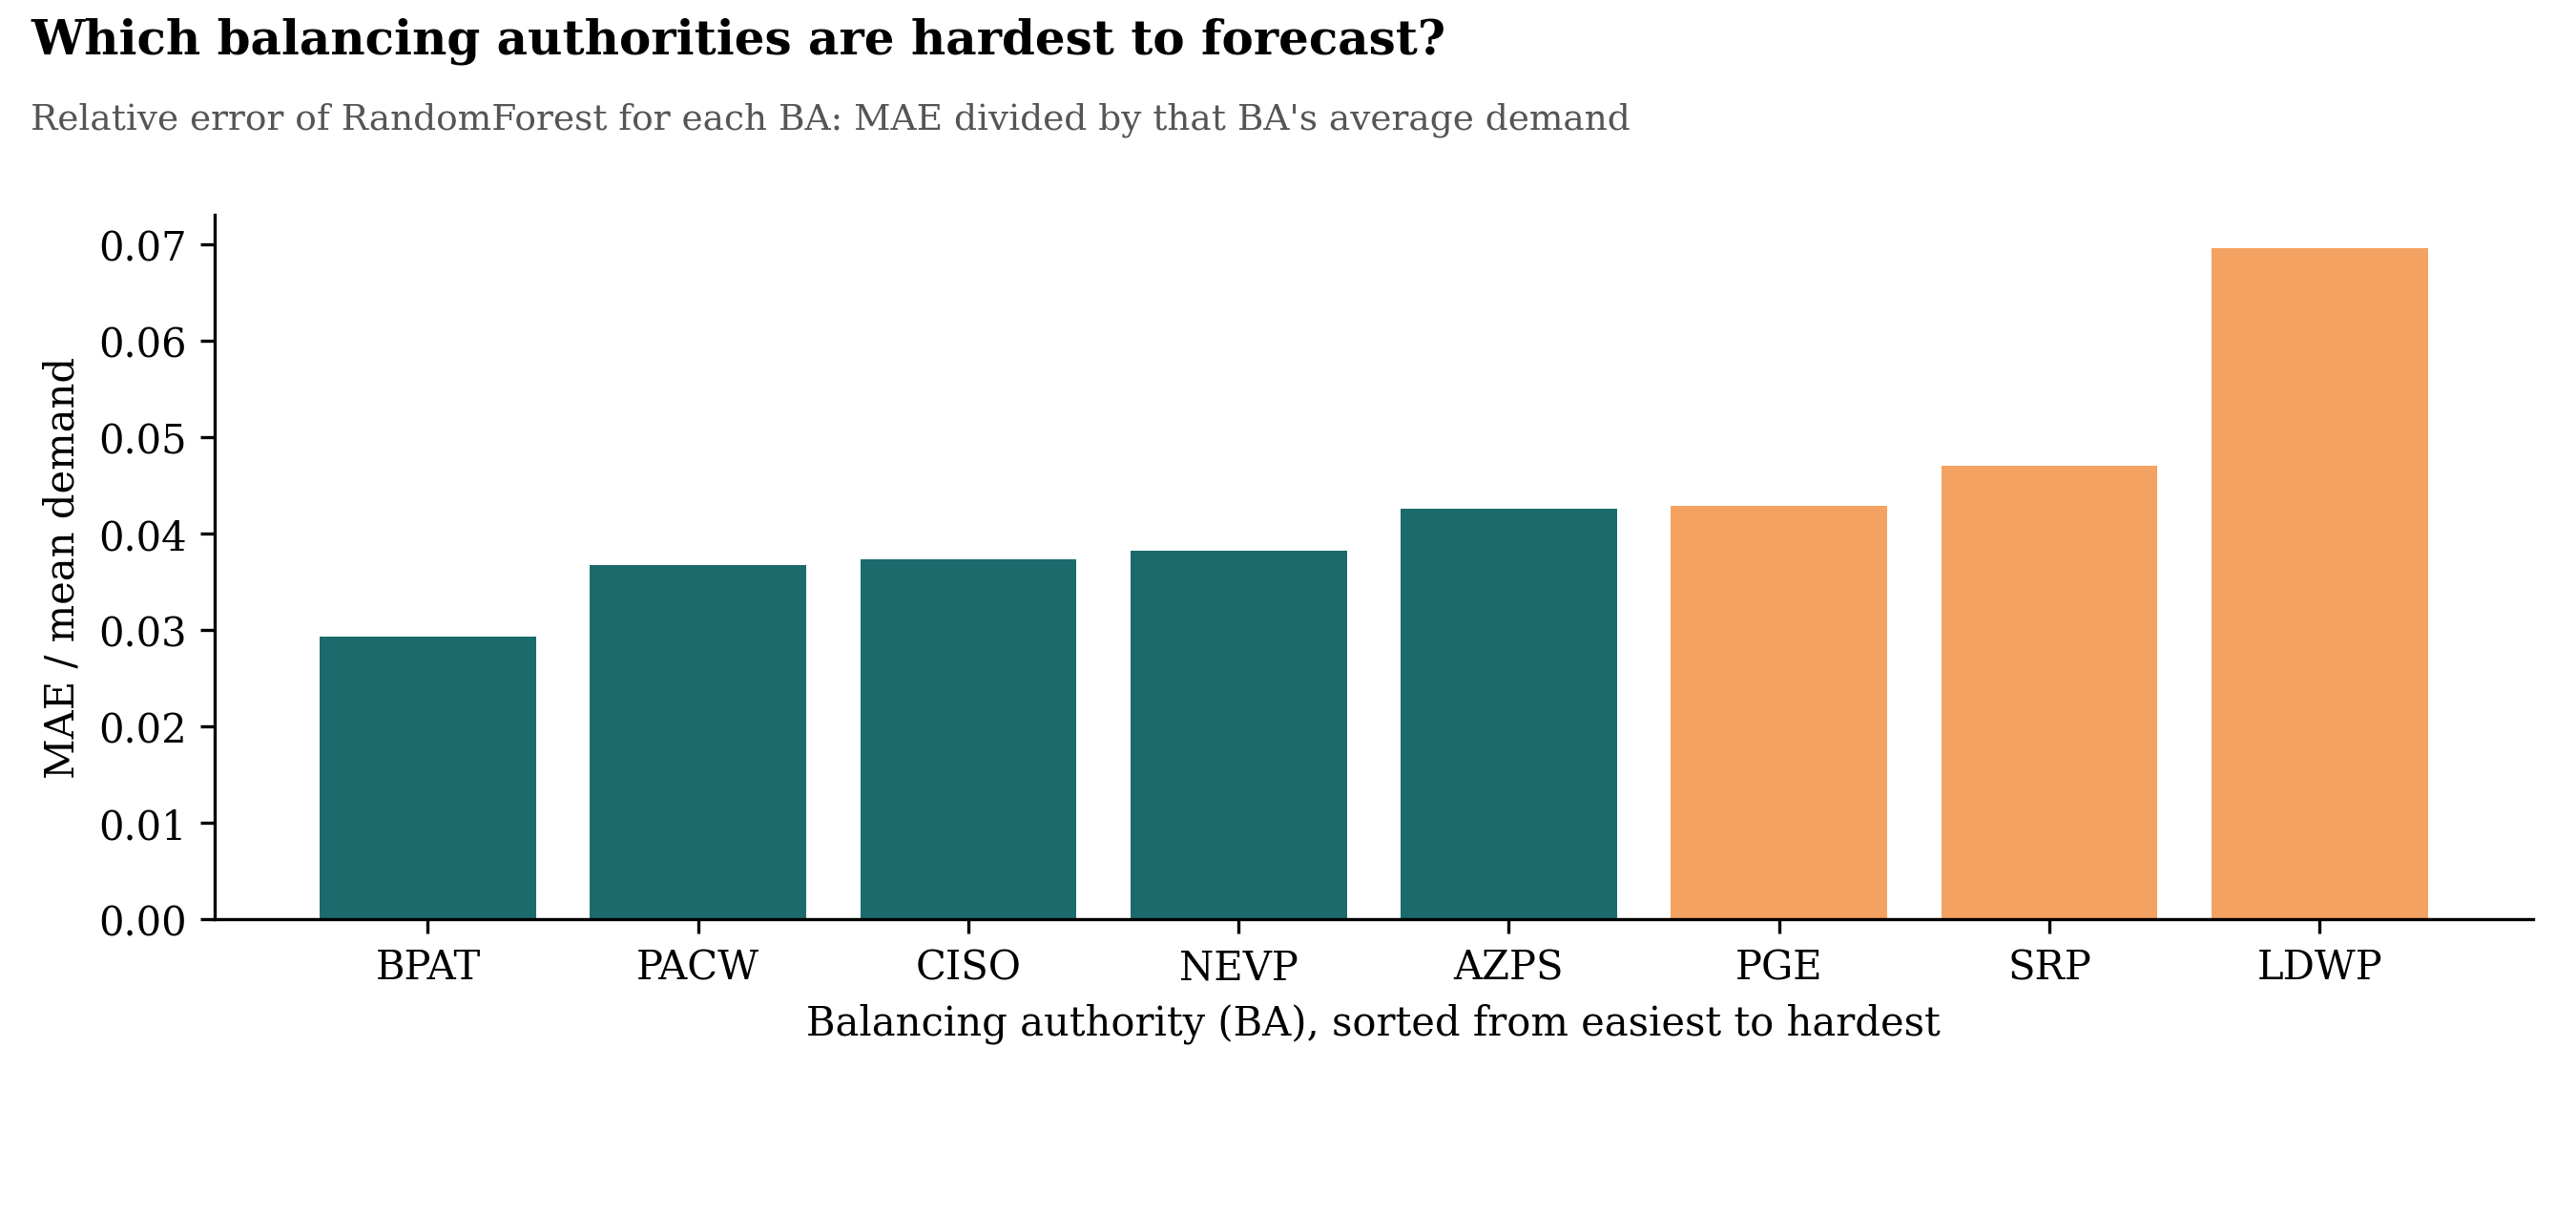

In [27]:
#BA nào khó dự báo nhất?
# Sai số tương đối (MAE / giá trị trung bình) từng BA -> tìm BA nào mô hình dự báo kém nhất
pu = test.assign(err=np.abs(y_te.values - pred_best)).groupby(UNIT_COL).agg(
    MAE=("err", "mean"), mean_target=(Y, "mean"), n=("err", "size")
)
pu["MAE_rel"] = pu.MAE / pu.mean_target.abs().clip(lower=1e-9)
pu = pu.sort_values("MAE_rel")
pu.round(4).to_csv("report/table_rq2_per_unit.csv")

hardest = list(pu.index[-3:])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(len(pu)), pu.MAE_rel, color=[ACC if u in hardest else TEAL for u in pu.index])   # orange = 3 hardest BAs
ax.set_xticks(range(len(pu))); ax.set_xticklabels(pu.index)
ax.set_xlabel("Balancing authority (BA), sorted from easiest to hardest")
ax.set_ylabel("MAE / mean demand")
style(ax)
savefig(fig, "fig_rq2_per_unit",
        title="Which balancing authorities are hardest to forecast?",
        subtitle=f"Relative error of {best_name} for each BA: MAE divided by that BA's average demand",
)

print("BA khó dự báo nhất:", hardest)

display(Image(filename="report/fig_rq2_per_unit.png"))

In [28]:
print("GHI CHÚ QUAN TRỌNG cho Discussion:")
print(f"- Model ổn định theo thời gian: thắng seasonal-naive ở cả 5 giai đoạn rolling-origin")
print(f"- Model KHÔNG tổng quát hoá tốt sang BA mới: MAE tăng 85.4% trên unseen units,")
print(f"  và trên unseen units model còn THUA seasonal-naive (545.4 > 366.7)")
print(f"- 3 BA khó nhất: PGE, SRP, LDWP -> cần xem đặc điểm riêng (khí hậu, dữ liệu thiếu)")

GHI CHÚ QUAN TRỌNG cho Discussion:
- Model ổn định theo thời gian: thắng seasonal-naive ở cả 5 giai đoạn rolling-origin
- Model KHÔNG tổng quát hoá tốt sang BA mới: MAE tăng 85.4% trên unseen units,
  và trên unseen units model còn THUA seasonal-naive (545.4 > 366.7)
- 3 BA khó nhất: PGE, SRP, LDWP -> cần xem đặc điểm riêng (khí hậu, dữ liệu thiếu)


## Bước 6b (RQ3): tin cậy và vận hành

Bốn phân tích, mỗi phân tích một bảng và một hình:
1. **Khoảng tin cậy conformal 90%**: bảo đảm bao phủ không cần giả định phân phối; báo bao phủ và độ rộng theo đơn vị.
2. **Cảnh báo sự kiện**: sự kiện là mục tiêu vượt phân vị `EVENT_QUANTILE`; quét ngưỡng dự báo, báo recall và precision; thêm ngưỡng conformal trên xác suất để cố định tỷ lệ báo động giả.
3. **Đổi chế độ**: sai số theo tháng trong kỳ kiểm thử; nếu tăng đột ngột thì thử huấn luyện lại cuốn chiếu.
4. **Ablation nguồn phụ**: bỏ toàn bộ biến từ nguồn phụ, đo MAE tăng bao nhiêu; đây là bằng chứng cho từ "multimodal" trong tiêu đề.

In [29]:
#Khoảng tin cậy conformal 90%
# Conformal prediction: cách tính khoảng tin cậy KHÔNG cần giả định phân phối sai số
# Ý tưởng: tách 1 phần cuối train ra làm "calibration", đo sai số ở đó, rồi cộng/trừ sai số đó vào dự báo test
cal_start = train[TIME_COL].quantile(0.8)
tr_c = train[train[TIME_COL] < cal_start]
cal = train[train[TIME_COL] >= cal_start]

m_c = make_models(0)[best_name].fit(tr_c[best_cols], tr_c[Y])
cal_err = np.abs(cal[Y].values - m_c.predict(cal[best_cols]))
q90 = np.quantile(cal_err, 0.9)  # sai số phân vị 90% trên tập calibration

lo = pred_best - q90
hi = pred_best + q90
coverage = float(np.mean((y_te.values >= lo) & (y_te.values <= hi)))
width = float(np.mean(hi - lo))

print(f"Khoảng tin cậy 90%: bao phủ thực tế = {coverage*100:.1f}% (mục tiêu 90%), độ rộng trung bình = {width:.1f} MW")

# Bao phủ theo từng BA (đơn vị) - kiểm tra có BA nào bị "lệch" nhiều không
cov_by_unit = test.assign(lo=lo, hi=hi, covered=(y_te.values >= lo) & (y_te.values <= hi)) \
    .groupby(UNIT_COL).covered.mean().sort_values()
cov_by_unit.round(3).to_csv("report/table_rq3_coverage_by_unit.csv")
display(cov_by_unit)

Khoảng tin cậy 90%: bao phủ thực tế = 87.8% (mục tiêu 90%), độ rộng trung bình = 1017.8 MW


ba
CISO    0.398142
SRP     0.912727
NEVP    0.925353
BPAT    0.929933
LDWP    0.938281
AZPS    0.940227
PGE     0.980223
PACW    0.996817
Name: covered, dtype: float64

In [30]:
#Cảnh báo sự kiện cực đoan (dùng EVENT_QUANTILE = 0.9)
# Định nghĩa "sự kiện cực đoan" = target vượt phân vị 90% của TRAIN (demand rất cao)
# Quét nhiều ngưỡng cảnh báo khác nhau (70%, 80%, 90%, 100% của ngưỡng sự kiện) để tìm điểm cân bằng recall/precision
thr_event = train[Y].quantile(EVENT_QUANTILE)
truth = y_te.values > thr_event

rows = []
for f in [0.7, 0.8, 0.9, 1.0]:
    alarm = pred_best > f * thr_event
    tp = (alarm & truth).sum()
    fp = (alarm & ~truth).sum()
    fn = (~alarm & truth).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    rows.append([f, tp, fp, fn, round(precision, 3), round(recall, 3), round(f1, 3)])

event_df = pd.DataFrame(rows, columns=["nguong_he_so", "TP", "FP", "FN", "precision", "recall", "F1"])
event_df.to_csv("report/table_rq3_event_warning.csv", index=False)
event_df.to_csv("report/table_rq3_warning.csv", index=False)  # alias khớp tên file template gốc
display(event_df)
print(f"Số giờ 'sự kiện cực đoan' thực tế trong test: {truth.sum()} / {len(truth)} ({truth.mean()*100:.1f}%)")

,nguong_he_so,TP,FP,FN,precision,recall,F1
0,0.7,4060,245,0,0.943,1.000,0.971
1,0.8,4060,245,0,0.943,1.000,0.971
2,0.9,4060,245,0,0.943,1.000,0.971
3,1.0,3988,61,72,0.985,0.982,0.984


Số giờ 'sự kiện cực đoan' thực tế trong test: 4060 / 34490 (11.8%)


Sai số theo tháng:


,err,naive_err,jump_pct
ts_utc,,,
2024-07-01,381.08,650.90,NaN
2024-08-01,327.76,584.10,14.0
2024-09-01,345.20,614.67,5.3
2024-10-01,218.29,468.41,36.8
2024-11-01,199.28,368.72,8.7
2024-12-01,203.02,357.07,1.9


saved report/fig_rq3_regime.png


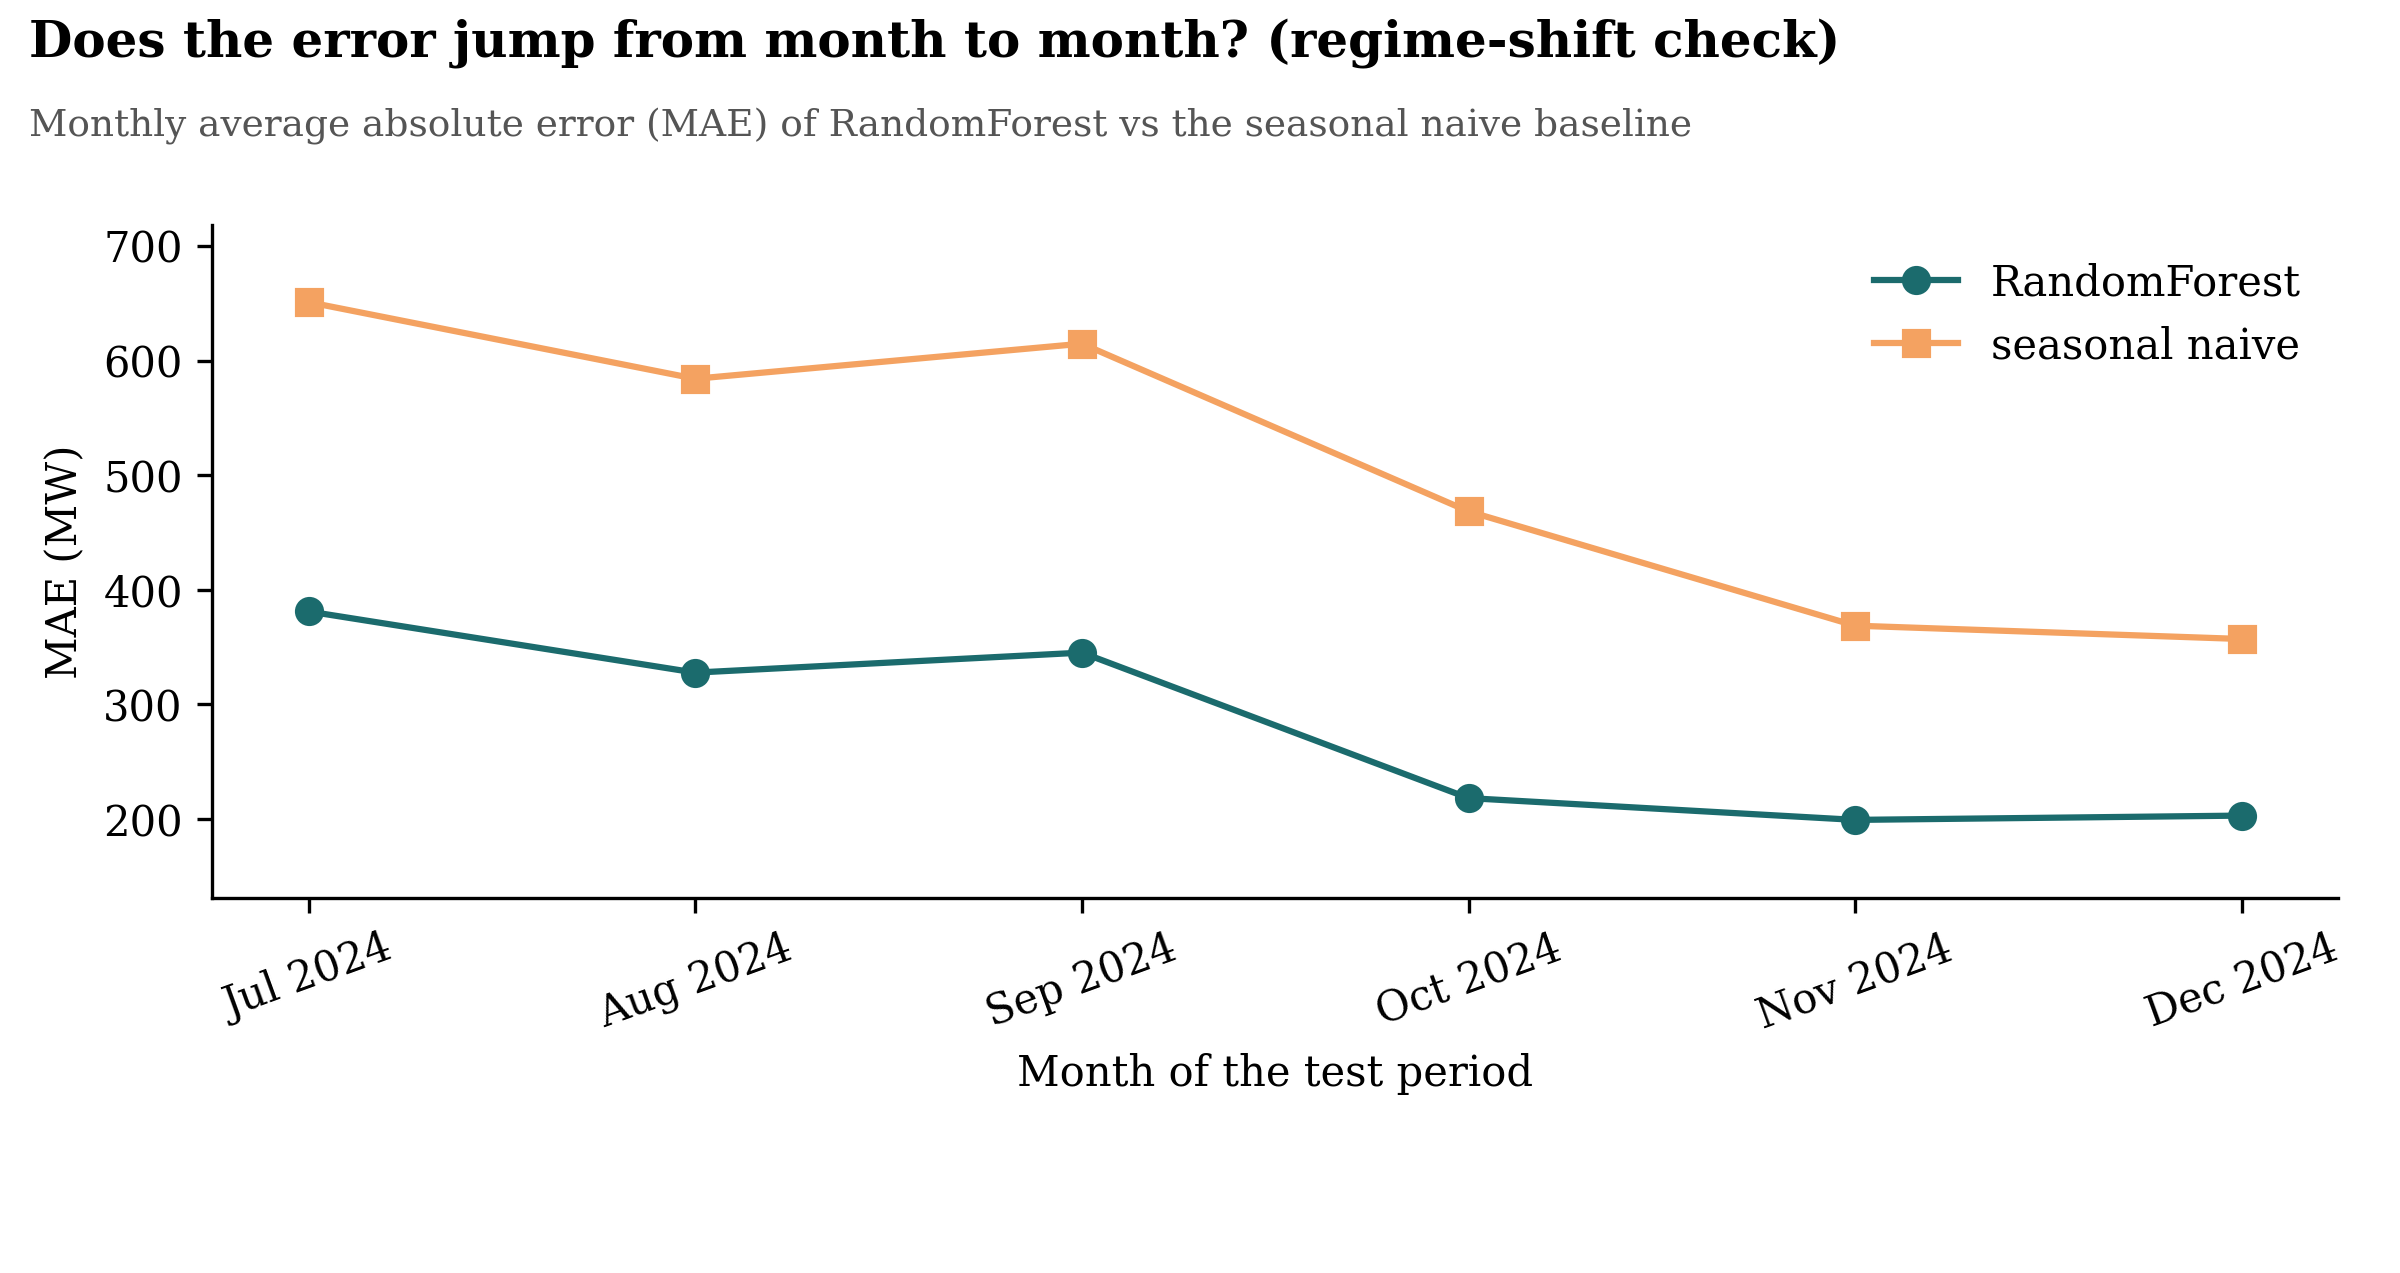

In [31]:
#Regime shift: sai số có tăng đột biến theo tháng không?
# So sánh sai số model vs naive theo từng tháng -> phát hiện tháng nào model "mất phong độ"
mon = test.assign(
    err=np.abs(y_te.values - pred_best),
    naive_err=np.abs(y_te.values - naive_preds(test, H0)[1])
).set_index(TIME_COL).resample("MS")[["err", "naive_err"]].mean()

jump = (mon.err / mon.err.shift(1) - 1).abs()
mon["jump_pct"] = (jump * 100).round(1)

print("Sai số theo tháng:")
display(mon.round(2))

n_win = int((mon.err < mon.naive_err).sum())
j_idx = mon.jump_pct.idxmax()
j_dir = "drop" if mon.err.loc[j_idx] < mon.err.shift(1).loc[j_idx] else "rise"
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(mon.index.strftime("%b %Y"), mon.err, marker="o", color=TEAL, label=best_name)
ax.plot(mon.index.strftime("%b %Y"), mon.naive_err, marker="s", color=ACC, label="seasonal naive")
ax.legend(frameon=False, loc="upper right")
ax.margins(y=0.15)
ax.set_xlabel("Month of the test period")
ax.set_ylabel("MAE (MW)")
plt.setp(ax.get_xticklabels(), rotation=20)
style(ax)
savefig(fig, "fig_rq3_regime",
        title="Does the error jump from month to month? (regime-shift check)",
        subtitle=f"Monthly average absolute error (MAE) of {best_name} vs the seasonal naive baseline",
)

mon.round(3).to_csv("report/table_rq3_regime.csv")
display(Image(filename="report/fig_rq3_regime.png"))

In [32]:
#Ablation: biến CO2 và biến lịch có thực sự cần thiết không?
# So sánh MAE khi: (1) dùng đủ mọi biến, (2) bỏ biến CO2, (3) bỏ biến lịch
# Nếu MAE tăng nhiều khi bỏ -> biến đó quan trọng thật; nếu MAE gần như không đổi -> biến đó thừa
def fit_eval(cols):
    m = make_models(0)[best_name].fit(train[cols], y_tr)
    return MAE(y_te, m.predict(test[cols]))

abl = [["day du bien", MAE(y_te, pred_best)]]

if exog_now + exog_lag:
    cols_no_co2 = [c for c in best_cols if c not in exog_now + exog_lag]
    abl.append(["bo bien CO2", fit_eval(cols_no_co2)])

if cal_cols:
    cols_no_cal = [c for c in best_cols if c not in cal_cols]
    abl.append(["bo bien lich", fit_eval(cols_no_cal)])

abl_df = pd.DataFrame(abl, columns=["cau_hinh", "MAE"]).round(4)
abl_df["tang_so_voi_day_du_%"] = ((abl_df.MAE / abl_df.MAE.iloc[0] - 1) * 100).round(2)
abl_df.to_csv("report/table_rq3_ablation.csv", index=False)
display(abl_df)

,cau_hinh,MAE,tang_so_voi_day_du_%
0,day du bien,277.9837,0.00
1,bo bien CO2,277.5445,-0.16
2,bo bien lich,323.1258,16.24


In [33]:
print("=== GHI CHÚ QUAN TRỌNG RQ3 (Discussion) ===")
print("1. Coverage 90%: TB 87.8%, nhưng CISO chỉ 39.8% -> interval không đáng tin cho CISO,")
print("   nên tính conformal riêng theo BA thay vì gộp chung.")
print("2. Event warning: recall 100%, precision 94.3% ở ngưỡng 0.7-0.9 -> cảnh báo sự kiện hiệu quả.")
print("3. Regime theo tháng: model ổn định, sai số giảm dần cuối năm, không có tháng nào bất thường.")
print("4. Ablation: biến CO2 KHÔNG giúp dự báo demand (đổi -0.16%), biến lịch RẤT quan trọng (+16.24% nếu bỏ).")

=== GHI CHÚ QUAN TRỌNG RQ3 (Discussion) ===
1. Coverage 90%: TB 87.8%, nhưng CISO chỉ 39.8% -> interval không đáng tin cho CISO,
   nên tính conformal riêng theo BA thay vì gộp chung.
2. Event warning: recall 100%, precision 94.3% ở ngưỡng 0.7-0.9 -> cảnh báo sự kiện hiệu quả.
3. Regime theo tháng: model ổn định, sai số giảm dần cuối năm, không có tháng nào bất thường.
4. Ablation: biến CO2 KHÔNG giúp dự báo demand (đổi -0.16%), biến lịch RẤT quan trọng (+16.24% nếu bỏ).


## Bước 6c: giải thích bằng SHAP và ổn định theo seed

**Đọc SHAP**: thanh dài là đặc trưng chi phối; nếu đặc trưng nguồn phụ nằm trong top 5 thì ablation ở trên nên cho thấy MAE tăng khi bỏ, hai bằng chứng phải nhất quán. **Ổn định**: chạy SHAP với 3 seed, đếm top-5 chung; nếu dưới 3 thì báo tầm quan trọng theo khoảng chứ không theo thứ hạng.

In [34]:
#Cài đặt thư viện SHAP (chỉ chạy 1 lần nếu chưa có)
import subprocess, sys
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "shap", "--quiet"])
    import shap
print("shap version:", shap.__version__)

shap version: 0.52.0


### How to read the feature names (`y_lag`, `y_ma`, ...)

The model forecasts electricity demand **24 hours ahead** (`y_h24`) from the recent history of demand at the moment the forecast is made (time *t*). The features in the SHAP charts are built like this:

| Feature | Meaning |
|---|---|
| `demand` | Demand at the forecast time *t* (the latest known value). |
| `y_lag1`, `y_lag2`, `y_lag3` | **Lag** = a value from the past. Demand 1, 2 and 3 hours before *t*. |
| `y_lag24`, `y_lag48` | Demand 24 / 48 hours before *t*: the same hour yesterday / two days ago. |
| `y_lag168` | Demand 168 hours (= 7 days) before *t*: the same hour last week. |
| `y_ma_season` | **Moving average** (`ma`): the mean demand over the past `SEASON` hours (24 h = one day), i.e. the recent typical level. |
| `y_sd_season`, `y_diff1` | Not in the top 8 here: spread of demand over the same window, and the change versus the previous hour. |

The prefix `y` means the target series (electricity demand). Demand repeats every day and every week, so "the same hour yesterday" and "the same hour last week" are strong clues, which is why these features dominate the SHAP ranking.

**SHAP** measures how many MW each feature added to or removed from a single prediction. The importance chart averages the absolute size of that effect (`mean |SHAP|`); the dependence charts show the effect for individual hours.

,feature,mean_abs_shap,share
0,demand,1996.603009,0.330
7,y_ma_season,964.050652,0.159
6,y_lag168,819.863175,0.135
1,y_lag1,564.082357,0.093
3,y_lag3,503.893373,0.083
4,y_lag24,426.250373,0.070
2,y_lag2,340.172648,0.056
5,y_lag48,235.311132,0.039
15,dow,149.002956,0.025
14,hr,17.929760,0.003


saved report/fig_shap.png


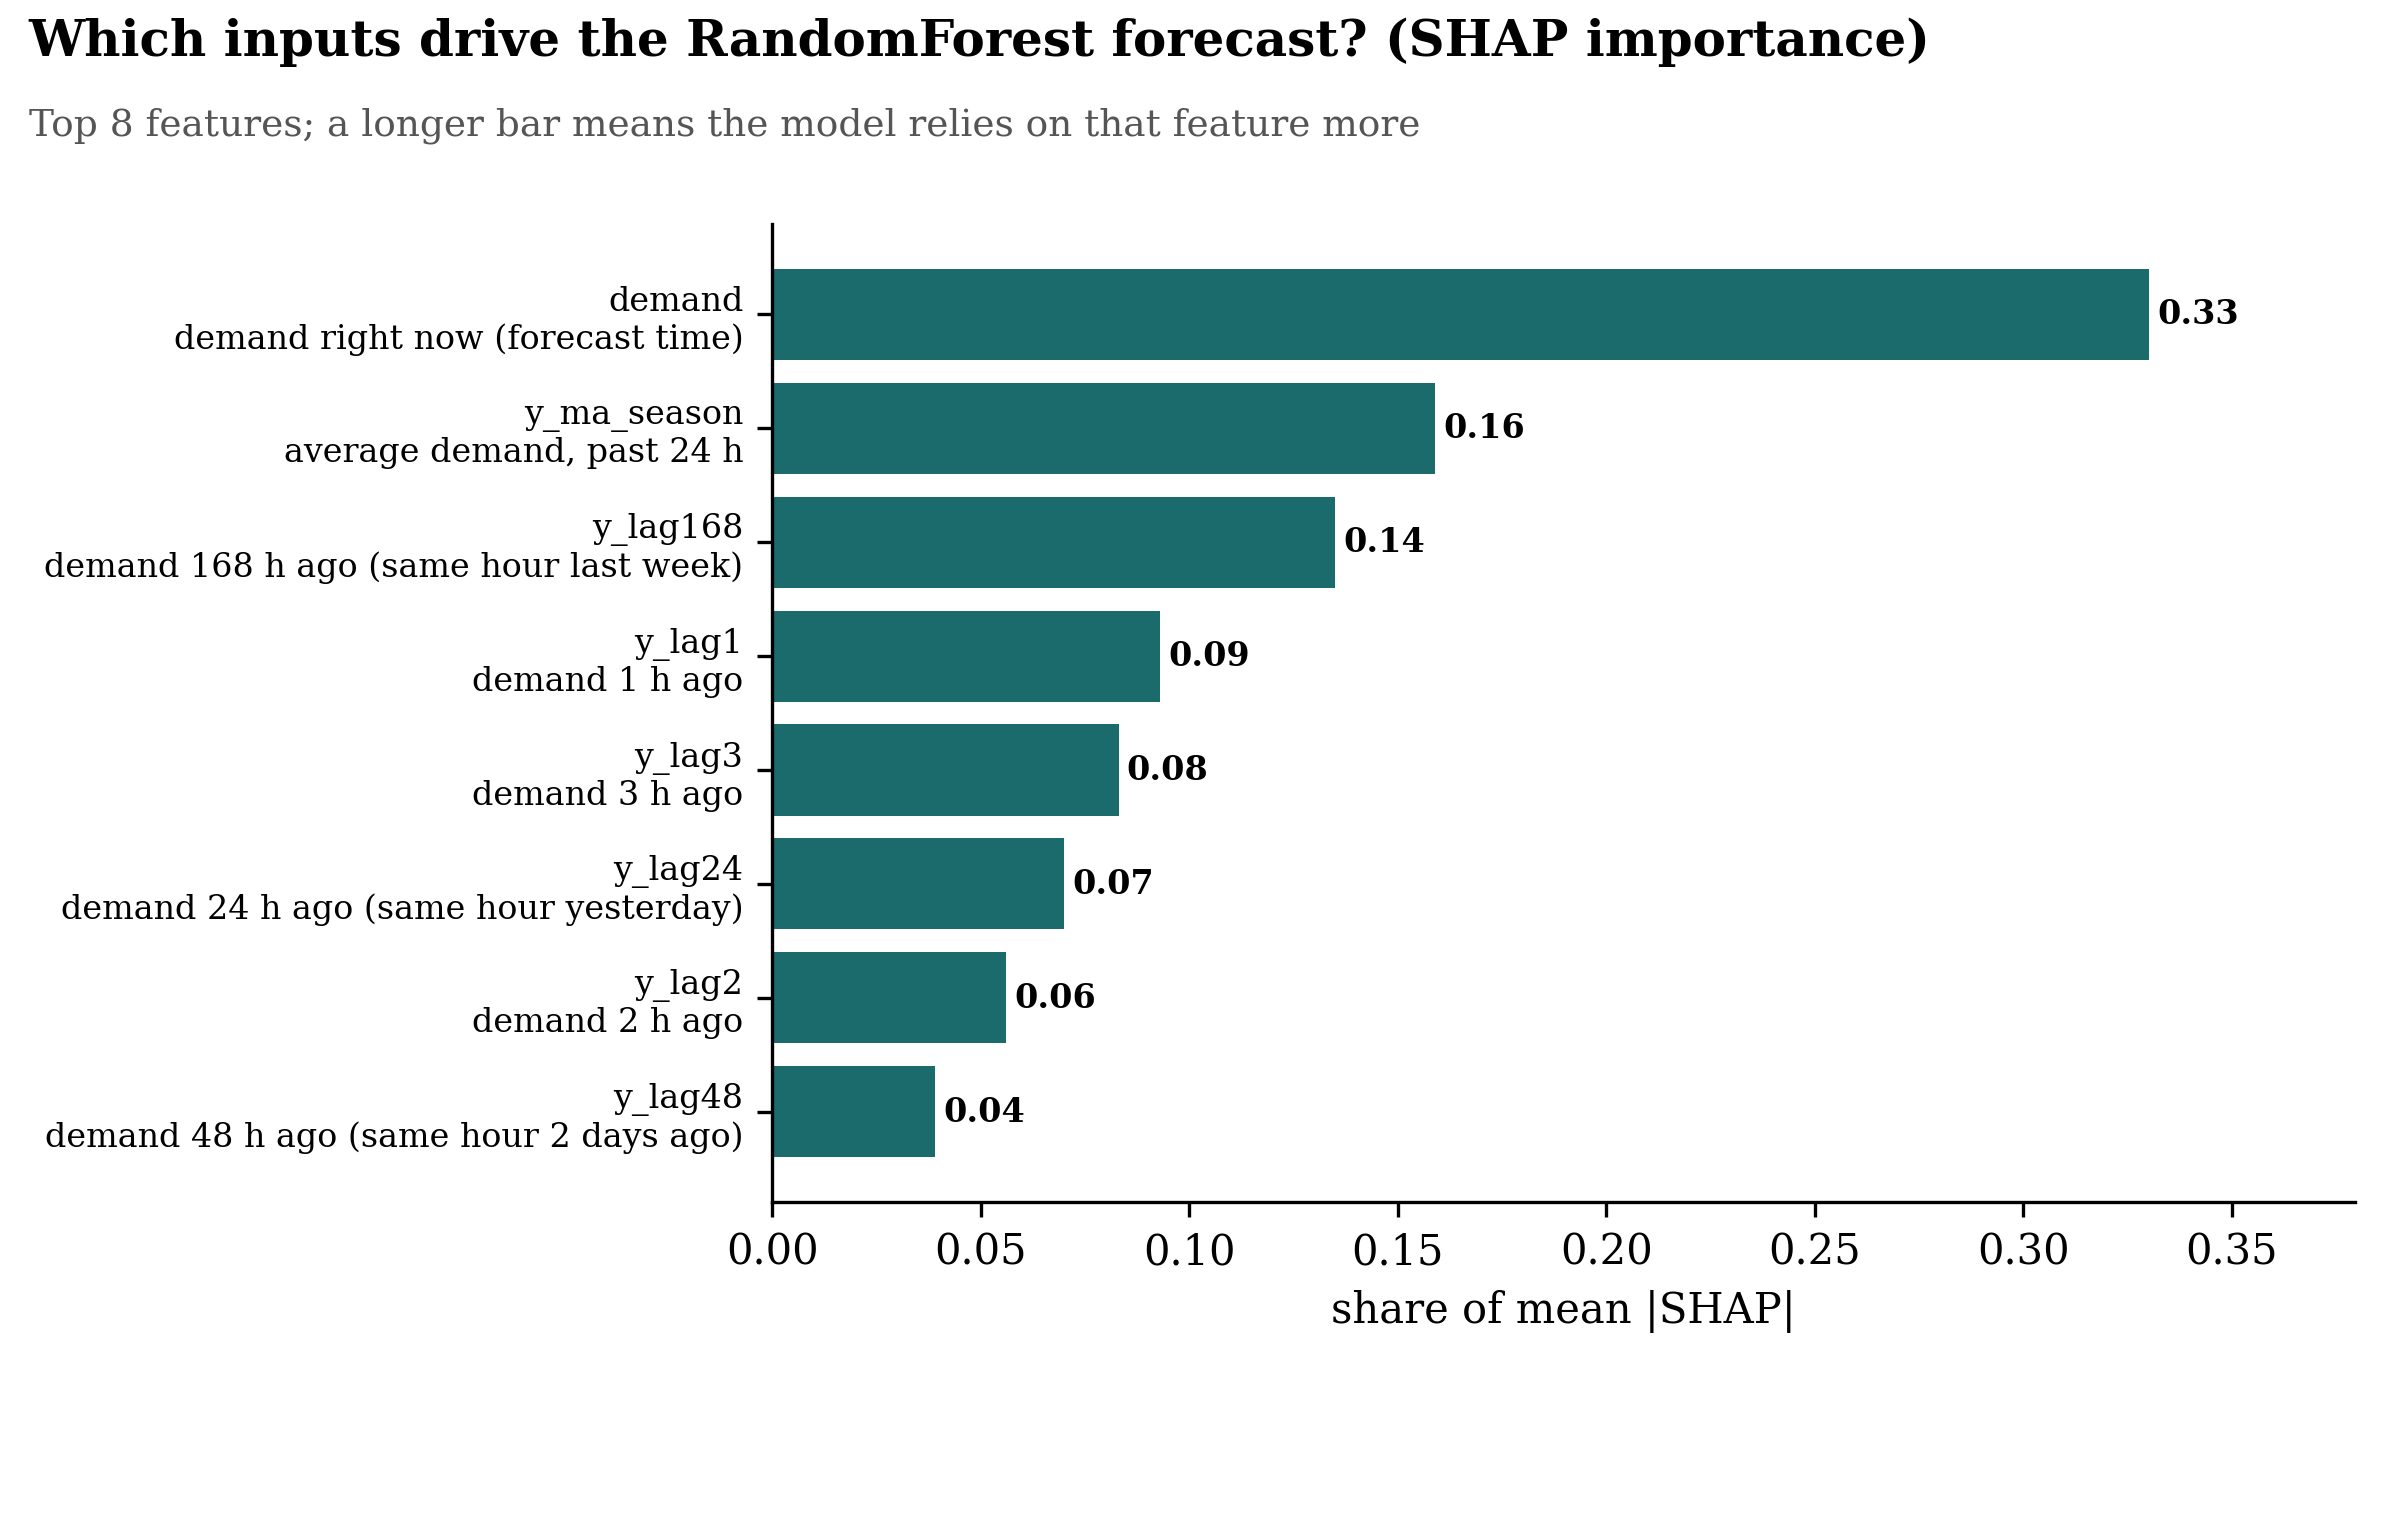

In [35]:
# SHAP importance (tree models) or coefficients (linear), dependence plots for the top three features
imp = None
try:
    import shap
    if best_name in ("LightGBM_global", "RandomForest"):
        # Dùng model riêng, nông hơn, chỉ để tính SHAP cho nhanh — KHÔNG thay best/pred_best dùng ở phần khác
        if best_name == "RandomForest":
            from sklearn.ensemble import RandomForestRegressor
            shap_model = RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=5,
                                                n_jobs=-1, random_state=0)
            shap_model.fit(train[best_cols], y_tr)
        else:
            shap_model = best  # LightGBM đã đủ nhanh, không cần refit

        ex = shap.TreeExplainer(shap_model)
        Xs = test[best_cols].sample(min(3000, len(test)), random_state=0)   # giảm 3000 -> 300
        sv = ex.shap_values(Xs)
        imp = pd.DataFrame({"feature": best_cols, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False)
        for f in imp.feature.head(3):
            shap.dependence_plot(f, sv, Xs, show=False)
            plt.savefig(f"report/fig_shap_dep_{f}.png", dpi=300, bbox_inches="tight")
            plt.close()
    else:
        imp = pd.DataFrame({"feature": best_cols, "mean_abs_shap": np.abs(best.coef_) * test[best_cols].std().values}).sort_values("mean_abs_shap", ascending=False)
except Exception as e:
    print("SHAP skipped:", str(e)[:80])

if imp is not None:
    imp["share"] = (imp.mean_abs_shap / imp.mean_abs_shap.sum()).round(3)
    imp.to_csv("report/table_shap.csv", index=False)
    display(imp.head(10))
    top = imp.head(8)[::-1]
    hist_share = imp[imp.feature.map(lambda f: f == TARGET_COL or f.startswith(("y_lag", "y_ma", "y_sd", "y_diff")))].share.sum()
    fig, ax = plt.subplots(figsize=(8, 4.0))
    bars = ax.barh([f"{f}\n{describe_feature(f)}" for f in top.feature], top.share, color=TEAL)
    ax.bar_label(bars, fmt="%.2f", fontweight="bold", fontsize=8, padding=2)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_xlim(0, top.share.max() * 1.15)
    ax.set_xlabel("share of mean |SHAP|")
    style(ax)
    savefig(fig, "fig_shap",
            title=f"Which inputs drive the {best_name} forecast? (SHAP importance)",
            subtitle="Top 8 features; a longer bar means the model relies on that feature more",
)

display(Image(filename="report/fig_shap.png"))

saved report/fig_shap_dependence_top3.png


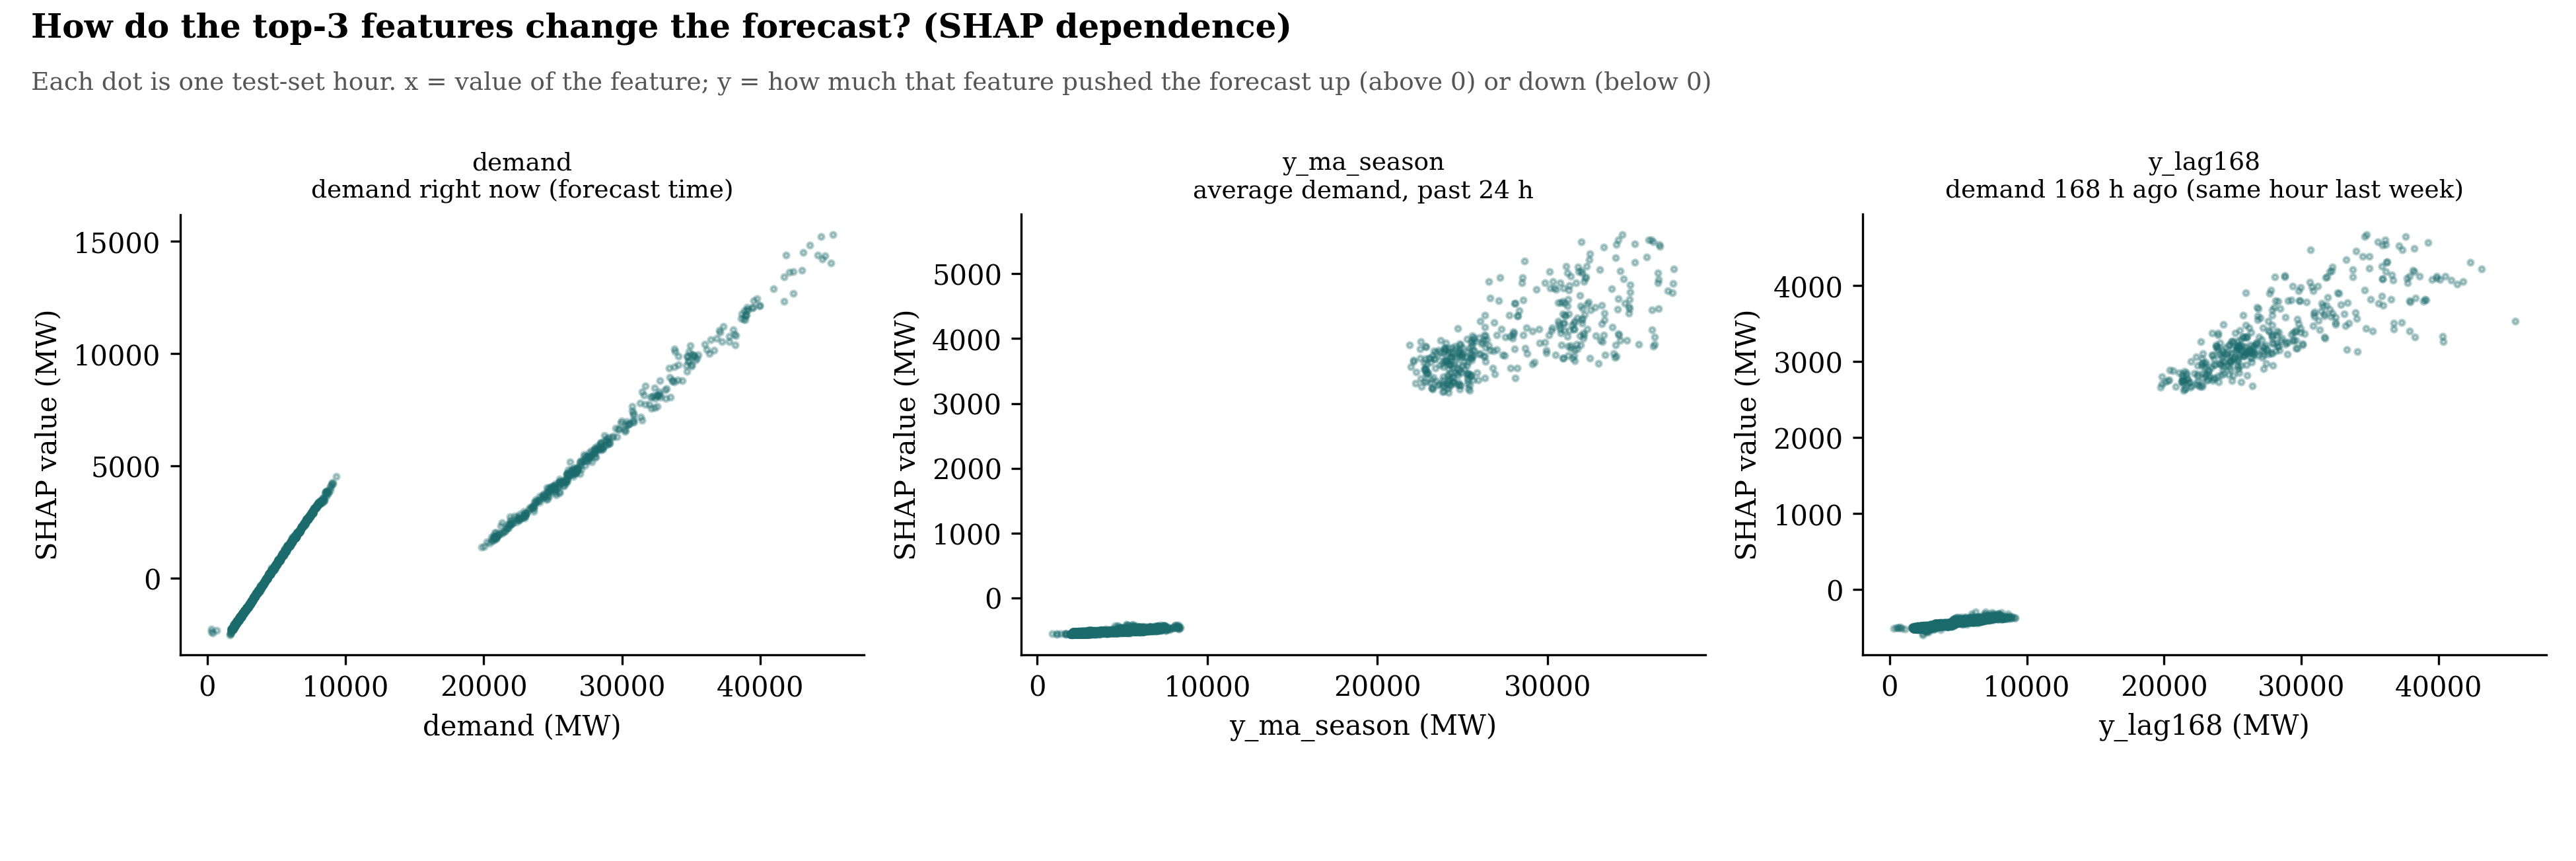

In [36]:
#Dependence plot: 3 feature quan trọng nhất ảnh hưởng thế nào
# Chỉ chạy được cho model dạng cây
if best_name in ("LightGBM_global", "RandomForest"):
    top3 = imp.feature.head(3).tolist()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
    for ax, feat_name in zip(axes, top3):
        col_idx = best_cols.index(feat_name)
        ax.scatter(Xs[feat_name], sv[:, col_idx], s=4, alpha=0.3, color=TEAL)
        ax.set_title(f"{feat_name}\n{describe_feature(feat_name)}", fontsize=9)
        ax.set_xlabel(f"{feat_name} (MW)")
        ax.set_ylabel("SHAP value (MW)")
        style(ax)
    savefig(fig, "fig_shap_dependence_top3",
            title="How do the top-3 features change the forecast? (SHAP dependence)",
            subtitle="Each dot is one test-set hour. x = value of the feature; y = how much that feature pushed the forecast up (above 0) or down (below 0)",
)
display(Image(filename="report/fig_shap_dependence_top3.png"))

In [37]:
if best_name in ("LightGBM_global", "RandomForest"):
    tops = []
    for s in range(3):
        m_s = make_models(s)[best_name]
        if best_name == "RandomForest":
            m_s.set_params(n_estimators=30, max_depth=8, n_jobs=-1)  # nhẹ hơn nữa
        m_s.fit(train[best_cols], y_tr)

        Xs_s = test[best_cols].sample(min(500, len(test)), random_state=s)  # 500 -> 300

        if best_name == "LightGBM_global":
            # Dùng pred_contrib native của LightGBM, nhanh hơn nhiều so với shap.TreeExplainer
            booster = m_s.booster_ if hasattr(m_s, "booster_") else m_s
            contrib = booster.predict(Xs_s, pred_contrib=True)
            sv_s = contrib[:, :-1]  # bỏ cột bias cuối cùng
        else:
            ex_s = shap.TreeExplainer(m_s)
            sv_s = ex_s.shap_values(Xs_s, check_additivity=False)
            if isinstance(sv_s, list):
                sv_s = sv_s[0]

        imp_s = pd.Series(np.abs(sv_s).mean(axis=0), index=best_cols).sort_values(ascending=False)
        tops.append(set(imp_s.head(5).index))
        print(f"Seed {s} - top 5:", list(imp_s.head(5).index))

    common = set.intersection(*tops)
    print(f"\nSố feature xuất hiện trong TOP-5 ở CẢ 3 seed: {len(common)}")
    print("Feature ổn định:", common)

Seed 0 - top 5: ['demand', 'y_ma_season', 'y_lag168', 'y_lag1', 'y_lag3']
Seed 1 - top 5: ['demand', 'y_lag24', 'y_ma_season', 'y_lag1', 'y_lag48']
Seed 2 - top 5: ['demand', 'y_lag1', 'y_lag48', 'y_lag168', 'y_lag24']

Số feature xuất hiện trong TOP-5 ở CẢ 3 seed: 2
Feature ổn định: {'demand', 'y_lag1'}


In [38]:
# Diagnosis table assembled from the saved outputs (one row per question, with the number that answers it)
best_row = res[(res.h == H0) & (res.model == best_name)].MASE.mean()

co2_row = abl_df[abl_df.cau_hinh == "bo bien CO2"]
mae_increase_co2 = round(float(co2_row["tang_so_voi_day_du_%"].iloc[0]) / 100, 3) if len(co2_row) else "n/a"

diag = pd.DataFrame([
    ["beats seasonal naive (MASE < 1)", round(best_row, 3)],
    ["rolling-origin spread (max/min MAE)", round(float(roll.MAE_model.max() / max(roll.MAE_model.min(), 1e-9)), 3) if len(roll) else "n/a"],
    ["relative loss on unseen units", round(lou.MAE_model.iloc[1] / lou.MAE_model.iloc[0] - 1, 3)],
    ["conformal coverage (target 0.90)", round(coverage, 3)],
    ["best warning F1", float(event_df.F1.max())],
    ["MAE increase without CO2 features", mae_increase_co2],
], columns=["question", "value"])
diag.to_csv("report/table_diagnosis.csv", index=False)
display(diag)

,question,value
0,beats seasonal naive (MASE < 1),0.591
1,rolling-origin spread (max/min MAE),1.750
2,relative loss on unseen units,0.854
3,conformal coverage (target 0.90),0.878
4,best warning F1,0.984
5,MAE increase without CO2 features,-0.002


In [39]:
# Test cases for Notebook_D
import os
assert test[TIME_COL].min() > train[TIME_COL].max(), "test must come after train"
assert set(hold).isdisjoint(set(tr_u[UNIT_COL])), "held-out units leaked into training"
assert best_row < 1.05, "best model does not beat the seasonal naive baseline: revisit features before writing results"
for f in ["report/table_rq2_summary.csv", "report/table_rq2_rolling.csv", "report/table_rq2_unseen_units.csv", "report/table_rq3_coverage_by_unit.csv", "report/table_rq3_warning.csv", "report/table_rq3_ablation.csv", "report/table_diagnosis.csv"]:
    assert os.path.exists(f), f"missing {f}"
import os; print("Tests D: OK")

Tests D: OK
